# DSE4212/QF4212 Group Project — Project 1
## Data-Driven Credit Scoring Using Explainable Machine Learning (Group 6)

This single notebook contains all the code and results for the project, in the order the work was done.

| Part | Content |
|---|---|
| 1 | Data loading and initial EDA (full data, single variables only) |
| 2 | Feature engineering and feature EDA (training set only: features against the target) |
| 3 | Model code: the shared modelling workflow and the six models |
| 4 | Results: tuning and cross-validated comparison, final test evaluation, SHAP explainability, fairness |

**To re-run:** place this notebook next to a `data/` folder containing `german.data`, install the packages below, and run all cells from top to bottom.

Packages: `numpy`, `pandas`, `scikit-learn>1.8`, `matplotlib`, `seaborn`, `shap`, `jupyter`, `xgboost`, `lightgbm`, `tensorflow`

The saved outputs come from the group's final run. Part 4 takes several minutes to re-run because every model is tuned by grid search.

# Part 1 — Data loading and initial EDA
## 1.1 Constants and data loading code
The first line of each code cell in this section, `%%writefile <file>`, saves the cell's code to that file so that later cells can import it. It is not part of the code itself.

### `constants.py`
Shared constants: seed, CV folds, category labels, feature lists, protected attributes, SHAP groups.

In [1]:
%%writefile constants.py
from sklearn.model_selection import StratifiedKFold

SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

COLUMNS = ["checking", "duration", "history", "purpose", "amount", "savings", "employment",
           "installment_rate", "personal_status", "debtors", "residence_since", "property", "age",
           "other_plans", "housing", "n_credits", "job", "n_dependents", "telephone",
           "foreign_worker", "target"]

LABELS = {
    "checking": {"A11": "<0", "A12": "0-200", "A13": ">=200", "A14": "none"},
    "history": {"A30": "none/all paid", "A31": "all paid (this bank)", "A32": "existing paid",
                "A33": "past delay", "A34": "critical"},
    "purpose": {"A40": "new car", "A41": "used car", "A42": "furniture", "A43": "radio/tv",
                "A44": "appliances", "A45": "repairs", "A46": "education", "A47": "vacation",
                "A48": "retraining", "A49": "business", "A410": "other"},
    "savings": {"A61": "<100", "A62": "100-500", "A63": "500-1000", "A64": ">=1000", "A65": "unknown/none"},
    "employment": {"A71": "unemployed", "A72": "<1y", "A73": "1-4y", "A74": "4-7y", "A75": ">=7y"},
    "personal_status": {"A91": "male div/sep", "A92": "female div/sep/mar", "A93": "male single",
                        "A94": "male mar/wid", "A95": "female single"},
    "debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings/insurance", "A123": "car/other", "A124": "none"},
    "other_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "free"},
    "job": {"A171": "unskilled non-res", "A172": "unskilled res", "A173": "skilled", "A174": "highly skilled"},
    "telephone": {"A191": "no", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}

EMPLOYMENT_LEVEL = {"unemployed": 0, "<1y": 1, "1-4y": 2, "4-7y": 3, ">=7y": 4}
PROPERTY_LEVEL = {"none": 0, "car/other": 1, "savings/insurance": 2, "real estate": 3}
JOB_LEVEL = {"unskilled non-res": 0, "unskilled res": 1, "skilled": 2, "highly skilled": 3}
HOUSING_POINTS = {"free": 0, "rent": 1, "own": 2}
PURPOSE_TYPE = {"education": "professional", "retraining": "professional", "business": "professional",
                "new car": "needs", "used car": "needs", "furniture": "needs", "repairs": "needs",
                "vacation": "wants", "radio/tv": "wants",
                "appliances": "others", "other": "others"}

FEATURES = ["duration", "log_amount", "log_monthly_payment", "employment_level", "property_level",
            "installment_rate", "n_credits", "checking", "savings", "history", "purpose_type",
            "other_plans", "housing", "has_guarantor", "has_coapplicant", "thin_buffer",
            "duration_x_rate", "stability_score", "asset_score", "job_level"]

PROTECTED = ["sex", "foreign_worker", "age_less_30"]  # fairness only, never model inputs

NUMERIC = ["duration", "log_amount", "log_monthly_payment", "duration_x_rate", "stability_score"]
CATEGORICAL = ["checking", "savings", "history", "purpose_type", "other_plans", "housing"]
ORDINAL = ["employment_level", "property_level", "installment_rate", "n_credits", "job_level", "asset_score"]
BINARY = ["has_guarantor", "has_coapplicant", "thin_buffer"]
assert sorted(NUMERIC + ORDINAL + CATEGORICAL + BINARY) == sorted(FEATURES), "feature groups out of sync with FEATURES"

SHAP_GROUPS = {
    "log_amount": "credit amount", "log_monthly_payment": "credit amount",
    "duration": "loan duration", "duration_x_rate": "loan duration",
    "has_guarantor": "other debtors", "has_coapplicant": "other debtors",
    "stability_score": "stability", "employment_level": "stability",
    "asset_score": "assets", "property_level": "assets",
}

Writing constants.py


### `load_data.py`
Reads `data/german.data`, maps the coded categories to readable labels and creates `default` (1 = bad borrower).

In [2]:
%%writefile load_data.py
from pathlib import Path
import pandas as pd
from constants import (COLUMNS,LABELS)


DATA = Path(__file__).resolve().parent / "data" / "german.data"

def load_data(path=DATA):
    """
    Read german.data and return the full dataframe.
    Change the label (default) to 0/1 instead of 1/2
    """
    df = pd.read_csv(path, sep=" ", header=None, names=COLUMNS)
    for col, mapping in LABELS.items():
        df[col] = df[col].map(mapping)
    df["default"] = (df.pop("target") == 2).astype(int)  # raw coding: 1 = good, 2 = bad
    return df

Writing load_data.py


## 1.2 Initial EDA

### Initial EDA — German Credit Data
This file conducts initial analysis on the raw data.
Insights on the raw data seen here inform feature engineering that follows. 
To prevent leakage, no analysis is conducted on relationships between features and the target since a train test split has not been done yet.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from load_data import load_data

sns.set_theme(style="whitegrid")
df = load_data()
df.head()

,checking,duration,history,purpose,amount,savings,employment,installment_rate,personal_status,debtors,...,property,age,other_plans,housing,n_credits,job,n_dependents,telephone,foreign_worker,default
0,<0,6,critical,radio/tv,1169,unknown/none,>=7y,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0-200,48,existing paid,radio/tv,5951,<100,1-4y,2,female div/sep/mar,none,...,real estate,22,none,own,1,skilled,1,no,yes,1
2,none,12,critical,education,2096,<100,4-7y,2,male single,none,...,real estate,49,none,own,1,unskilled res,2,no,yes,0
3,<0,42,existing paid,furniture,7882,<100,4-7y,2,male single,guarantor,...,savings/insurance,45,none,free,1,skilled,2,no,yes,0
4,<0,24,past delay,new car,4870,<100,1-4y,3,male single,none,...,none,53,none,free,2,skilled,2,no,yes,1


## 1. Structure and data quality

In [4]:
print("Shape:", df.shape)
# Each row is a loan applicant/credit applicant and there are a 1000 such rows with 20 descriptors
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes.value_counts()

Shape: (1000, 21)
Missing values: 0
Duplicate rows: 0


str      13
int64     8
Name: count, dtype: int64

## 2. Target
`default` = 1 for bad credit (raw code 2). Imbalanced 70/30, so accuracy is misleading — we use AUC, precision/recall
and stratified splits throughout.

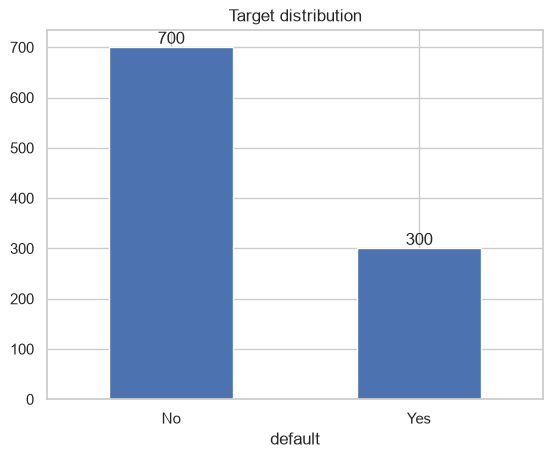

Default rate: 30.0%


In [5]:
counts = df["default"].value_counts().rename({0: "No", 1: "Yes"})
ax = counts.plot.bar(rot=0, title="Target distribution")
ax.bar_label(ax.containers[0])
plt.show()
print(f"Default rate: {df['default'].mean():.1%}")

## 3. Numerical variables

In [6]:
# Understanding the distributions, numerically and then visually
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
n_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
n_dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0
default,1000.0,0.30,0.46,0.0,0.0,0.0,1.00,1.0


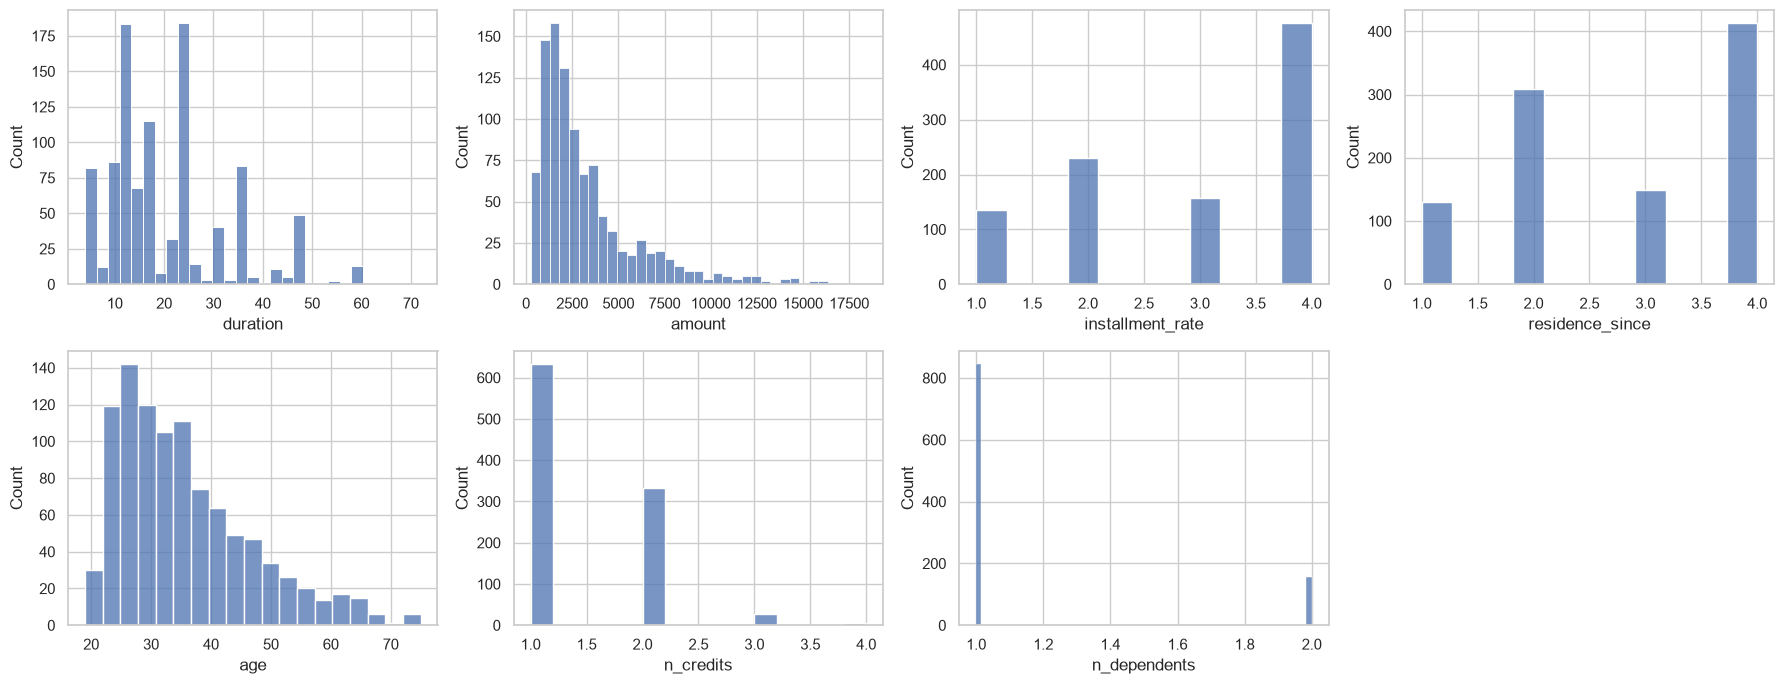

,skew
duration,1.09
amount,1.95
installment_rate,-0.53
residence_since,-0.27
age,1.02
n_credits,1.27
n_dependents,1.91


In [7]:
num_raw = ["duration", "amount", "installment_rate", "residence_since", "age", "n_credits", "n_dependents"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, num_raw):
    sns.histplot(data=df, x=col, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()
df[num_raw].skew().round(2).rename("skew").to_frame()
# significant right skew in the amount. These are not outliers, but fewer high ticket loans.
# a log transform will be used before modelling to address this skew. 
# skew value for n_dependents is also high but because there are only two possible values.

# duration and age also show right skew but are close to the standard practice high skew thresholds (>1).
# initial design will not transform these variables, which could be revisited if needed.

## 4. Categorical variables

In [8]:
cat_raw = df.select_dtypes(exclude="number").columns.tolist()

for col in cat_raw:
    counts = df[col].value_counts(dropna=False)
    tbl = pd.DataFrame({"count": counts, "percentage": (counts / len(df) * 100).round(1)})
    print(f"\n{col} ({df[col].nunique()} levels)")
    display(tbl)


checking (4 levels)


,count,percentage
checking,,
none,394,39.4
<0,274,27.4
0-200,269,26.9
>=200,63,6.3



history (5 levels)


,count,percentage
history,,
existing paid,530,53.0
critical,293,29.3
past delay,88,8.8
all paid (this bank),49,4.9
none/all paid,40,4.0



purpose (10 levels)


,count,percentage
purpose,,
radio/tv,280,28.0
new car,234,23.4
furniture,181,18.1
used car,103,10.3
business,97,9.7
education,50,5.0
repairs,22,2.2
appliances,12,1.2
other,12,1.2


... (16 outputs left out)


telephone (2 levels)


,count,percentage
telephone,,
no,596,59.6
yes,404,40.4



foreign_worker (2 levels)


,count,percentage
foreign_worker,,
yes,963,96.3
no,37,3.7


Notes:
1. Several variables have categories with very few occurences (for example, `purpose`). This motivates grouping of certain categories. 
2. Female single applicants do not occur in the dataset, making fairness analysis slightly less informative.
3. `foreign_worker` labels seem to be switched since the data suggests only 3.7% of loans were made to Germans. This will not be changed since there is no evidence, but will be flagged.
4. `sex`, `foreign_worker` and age are the candidate attributes for the fairness analysis, so they are not used as model inputs (if they were, any bias estimate would partly be a feature-importance measure). Section 5 tests whether `sex` can actually be recovered; both `sex` and `foreign_worker` turn out to have coding problems.

## 5. Coding check: `personal_status` (can we recover sex?)
Grömping (2019), *South German Credit Data: Correcting a Widely Used Data Set*, reports that the UCI documentation for this dataset has
several coding errors. For this variable, the corrected version states that male singles and female non-singles share the same code,
so sex cannot be recovered from it.

We cannot see the true labels, but we can test whether the documented labels are *plausible* without using the target.
If the documentation were right, we would expect:
- `male single` to be the youngest male group, with the fewest dependents;
- `male mar/wid` to be older, with more dependents;
- `female div/sep/mar` to look like one coherent group, not a mix of young singles and older married people.

,n,median_age,share_under_25,share_with_2_dependents
personal_status,,,,
male mar/wid,92,28.0,0.24,0.02
female div/sep/mar,310,29.0,0.27,0.05
male div/sep,50,36.0,0.02,0.06
male single,548,36.0,0.08,0.25


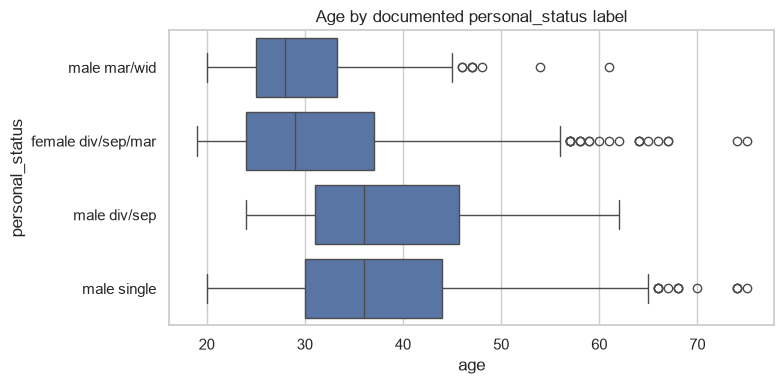

In [9]:
check = df.groupby("personal_status").agg(
    n=("age", "size"),
    median_age=("age", "median"),
    share_under_25=("age", lambda a: (a < 25).mean()),
    share_with_2_dependents=("n_dependents", lambda d: (d == 2).mean()),
).round(2).sort_values("median_age")
display(check)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="age", y="personal_status", order=check.index, ax=ax)
ax.set_title("Age by documented personal_status label")
plt.tight_layout()
plt.show()

Notes (fill in after running):
- Does the ordering of ages match the documented labels?
- Grömping's report and the corrected code table (`codetable.txt` in the UCI *South German Credit* download) give the authoritative mapping.
- If the labels look implausible, the derived `sex` variable is unreliable. Any fairness result by sex should then be reported as indicative only.

**Findings (attempt to recover sex)**

The documented labels do not fit the data:

| Documented label | n | Median age | Share under 25 | Share with 2 dependents |
|---|---|---|---|---|
| male single | 548 | 36 | 8% | 25% |
| male mar/wid | 92 | 28 | 24% | 2% |
| female div/sep/mar | 310 | 29 | 27% | 5% |
| male div/sep | 50 | 36 | 2% | 6% |
| female single | 0 | – | – | – |

1. **"male single" and "male mar/wid" look reversed.** The "single" group is older and is the group most likely to support two dependents (25%), which is the profile expected of married or widowed men. The "married/widowed" group is young (median 28, 24% under 25) and almost never has two dependents (2%), which is the profile of single people.
2. **"female div/sep/mar" is younger than expected** for a group of married, divorced or separated women (27% under 25). This is consistent with the corrected documentation (UCI *South German Credit*, Grömping 2019), which states that male singles and female non-singles share the same code, so this group is likely a mix of young single men and non-single women.
3. **No "female single" applicants exist**, which is implausible for a real credit sample of 1,000 people.

**Conclusion:** the attempt to recover sex from `personal_status` does not work. The documented labels are implausible, and at least one code is confirmed to mix men and women. One possible reading is that the 92 "male mar/wid" applicants are in fact single women, but this is **not clear as of now**: it is inferred from age and dependents patterns only, and we have not verified it against the official corrected code table. The derived `sex` variable is therefore unreliable, and any fairness result by sex is reported as indicative only.

# Part 2 — Feature engineering and feature EDA
## 2.1 Feature engineering code
The first line of each code cell in this section, `%%writefile <file>`, saves the cell's code to that file so that later cells can import it. It is not part of the code itself.

### `feature_engineering.py`
Engineered features and the single stratified 80/20 train/test split.

In [10]:
%%writefile feature_engineering.py
import numpy as np
from sklearn.model_selection import train_test_split
from constants import (SEED, EMPLOYMENT_LEVEL,PROPERTY_LEVEL,JOB_LEVEL,HOUSING_POINTS,PURPOSE_TYPE,
                       FEATURES,PROTECTED)
from load_data import load_data


def engineer(df):
    """Stateless features only: every row is transformed independently of the others."""
    df = df.copy()
    df["log_amount"] = np.log(df["amount"])
    df["log_monthly_payment"] = np.log(df["amount"] / df["duration"])  # no income field: affordability proxy
    df["employment_level"] = df["employment"].map(EMPLOYMENT_LEVEL)
    df["property_level"] = df["property"].map(PROPERTY_LEVEL)
    df["job_level"] = df["job"].map(JOB_LEVEL)
    df["purpose_type"] = df["purpose"].map(PURPOSE_TYPE)
    df["has_guarantor"] = (df["debtors"] == "guarantor").astype(int)
    df["has_coapplicant"] = (df["debtors"] == "co-applicant").astype(int)
    df["thin_buffer"] = ((df["checking"] == "<0") & (df["savings"] == "<100")).astype(int)
    df["duration_x_rate"] = df["duration"] * df["installment_rate"]
    # each component scaled to 0 to 1 so none dominates the sum
    df["stability_score"] = (df["employment_level"] / 4
                             + (df["residence_since"] - 1) / 3
                             + df["housing"].map(HOUSING_POINTS) / 2)
    df["asset_score"] = ((df["property"] == "real estate").astype(int)
                         + (df["housing"] == "own").astype(int)
                         + df["savings"].isin(["500-1000", ">=1000"]).astype(int))
    df["sex"] = np.where(df["personal_status"].str.startswith("female"), "female", "male")
    df["age_less_30"] = np.where(df["age"] <= 30, "30 or under", "over 30")
    return df


def get_data(test_size=0.2):
    df = engineer(load_data())
    train_idx, test_idx = train_test_split(
        df.index, test_size=test_size, stratify=df["default"], random_state=SEED)
    train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()

    return {"X_train": train[FEATURES], "X_test": test[FEATURES],
            "y_train": train["default"], "y_test": test["default"],
            "groups_train": train[PROTECTED], "groups_test": test[PROTECTED]}

Writing feature_engineering.py


## 2.2 Feature EDA (training set only)

### Post Feature Creation Analysis
This notebook only ever sees the train data since it is used to understand relationships between the features and the target. It is largely an exploratory step to augment understanding of what features are likely to be good predictors. Features will not be dropped solely on the basis of results found here, since all selected models are regularized or capable of feature selection in their own ways.

In [11]:
import numpy as np
import pandas as pd

from feature_engineering import get_data
from constants import FEATURES, NUMERIC, ORDINAL, CATEGORICAL, BINARY

pd.set_option("display.max_columns", 50)

In [12]:
data = get_data()
X = data["X_train"]
y = data["y_train"]
del data
# test data is not used anywhere

print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (800, 20) | y shape: (800,)


In [13]:
# 1. Feature set matches the plan
groups = NUMERIC + ORDINAL + CATEGORICAL + BINARY
assert set(groups) == set(X.columns) == set(FEATURES)
assert X.index.equals(y.index), "X and y index mismatch"
print("Feature groups OK:", len(groups), "features")

# 2. Class balance (expect about 30% default)
print("\nTrain default rate:", round(y.mean(), 4))
print(y.value_counts().rename({0: "good", 1: "bad"}))

# 3. Missing values and infinities
missing = X.isna().sum()
print("\nColumns with missing values:\n", missing[missing > 0] if missing.any() else "none")
num_cols = NUMERIC + ORDINAL + BINARY
inf_counts = np.isinf(X[num_cols]).sum()
print("Columns with infinities:\n", inf_counts[inf_counts > 0] if inf_counts.any() else "none")

# 4. Types and duplicates
print("\nDtypes:\n", X.dtypes.value_counts())
print("Duplicate rows:", X.duplicated().sum())

Feature groups OK: 20 features

Train default rate: 0.3
default
good    560
bad     240
Name: count, dtype: int64

Columns with missing values:
 none
Columns with infinities:
 none

Dtypes:
 int64      11
str         6
float64     3
Name: count, dtype: int64
Duplicate rows: 0


### Numerical Features
To explore the numerical/continuous features, we:
1. Plot box plots for the two target values (to see if there are differences in distribution)
2. Plot a correlation heatmap and find the VIFs of all the predictors to check for multicollinearity. Variables need not necessarily be dropped due to this due to the model selection.
3. Bin the variables and find the Information Value. This is standard practice in the credit industry to test the power of a predictor. However, with our sample size of 800, the IV estimates may be unstable. To address this, bootstrapping is performed to get a 95% CI for the IV instead of a point estimate.

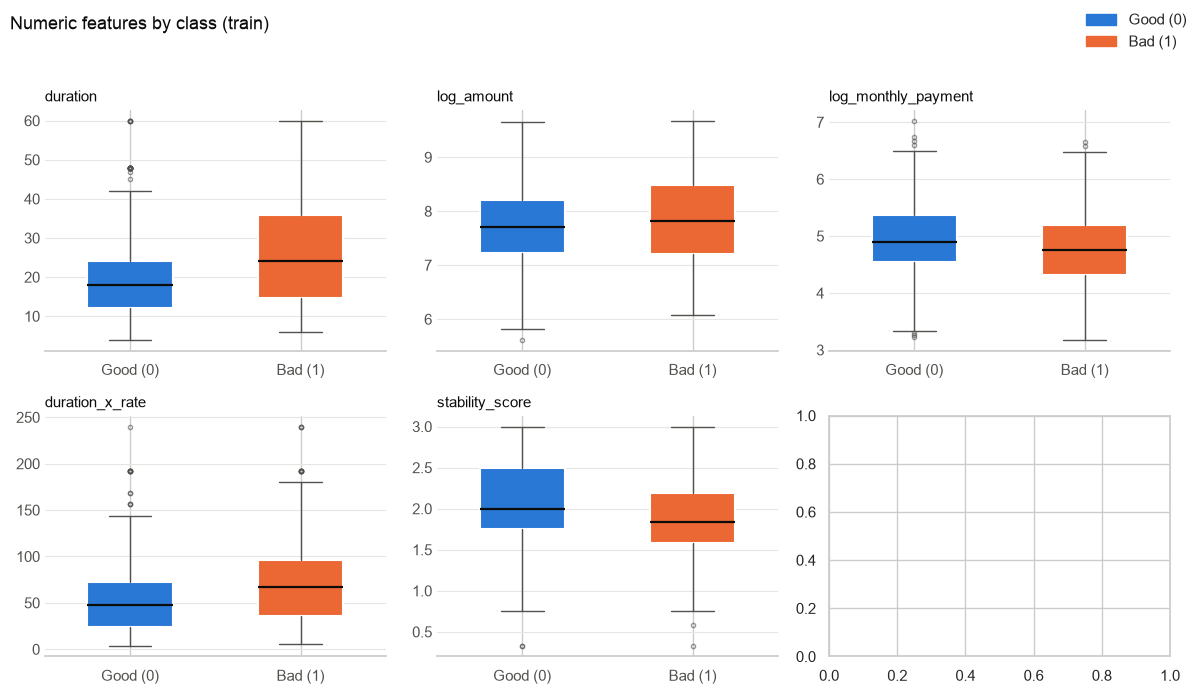

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

GOOD, BAD = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    groups = [X.loc[y == 0, col], X.loc[y == 1, col]]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5,
                    medianprops=dict(color=INK, linewidth=1.6),
                    whiskerprops=dict(color=MUTED, linewidth=1),
                    capprops=dict(color=MUTED, linewidth=1),
                    flierprops=dict(marker="o", markersize=3, markerfacecolor="none",
                                    markeredgecolor=MUTED, alpha=0.6))
    for box, colour in zip(bp["boxes"], [GOOD, BAD]):
        box.set(facecolor=colour, edgecolor="white", linewidth=1.5)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Good (0)", "Bad (1)"], color=MUTED)
    ax.set_title(col, color=INK, fontsize=11, loc="left")
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", colors=MUTED, length=0)

fig.legend(handles=[Patch(color=GOOD, label="Good (0)"), Patch(color=BAD, label="Bad (1)")],
           loc="upper right", frameon=False)
fig.suptitle("Numeric features by class (train)", x=0.01, ha="left", color=INK, fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Notes:
1. `Duration` and `log_amount` have wider distributions for the `bad` values and slightly higher medians.
2. `Stability_score` and `duration_x_rate` show clear difference in median, adding evidence to the value of these engineered variables.
3. Ordinal variables are not included here since boxplots are far less informative when the possible values are limited. They will be covered in the categorical sections.

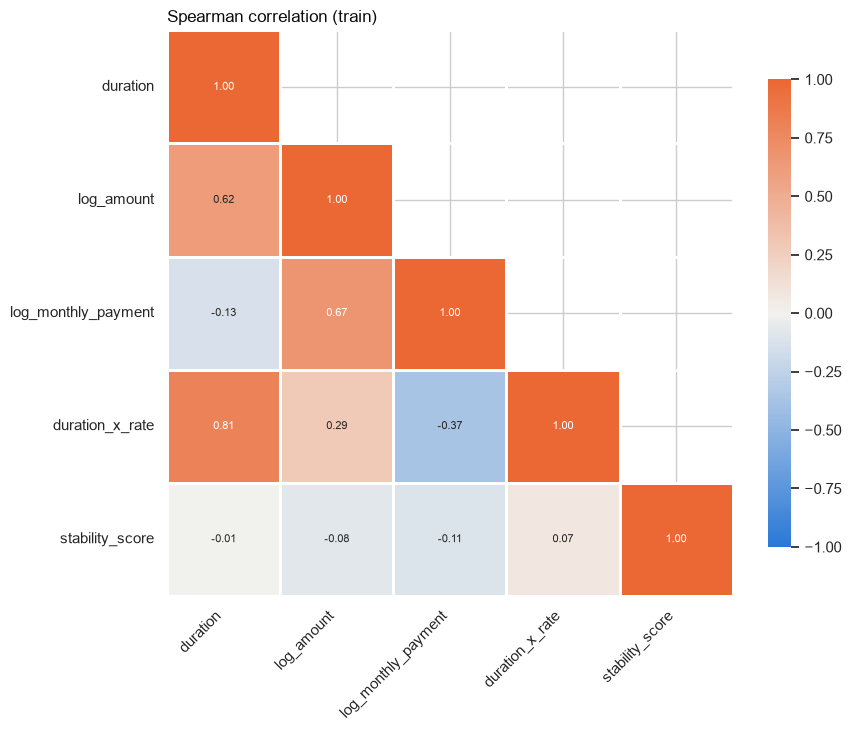

rho  abs_rho
duration_x_rate     duration             0.807    0.807
log_monthly_payment log_amount           0.666    0.666
log_amount          duration             0.622    0.622
duration_x_rate     log_monthly_payment -0.374    0.374
                    log_amount           0.290    0.290
log_monthly_payment duration            -0.125    0.125
stability_score     log_monthly_payment -0.111    0.111
                    log_amount          -0.081    0.081
                    duration_x_rate      0.074    0.074
                    duration            -0.005    0.005

In [15]:
import seaborn as sns

cols = NUMERIC
corr = X[cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the upper triangle
cmap = LinearSegmentedColormap.from_list("div", [GOOD, "#f2f1ee", BAD])

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=1, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation (train)", loc="left", color=INK)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# strongest pairs, for reading off quickly
pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack().rename("rho").to_frame()
pairs["abs_rho"] = pairs["rho"].abs()
display(pairs.sort_values("abs_rho", ascending=False).head(10).round(3))

In [16]:
def compute_vif(df):
    out = {}
    for col in df.columns:
        target = df[col].values.astype(float)
        others = np.column_stack([np.ones(len(df)), df.drop(columns=col).values.astype(float)])
        beta, *_ = np.linalg.lstsq(others, target, rcond=None)
        r_squared = 1 - (target - others @ beta).var() / target.var()
        out[col] = 1 / (1 - r_squared)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

vif = compute_vif(X[NUMERIC])
display(vif.round(2).to_frame())

,VIF
log_amount,18.47
duration,12.42
log_monthly_payment,11.14
duration_x_rate,3.44
stability_score,1.03


Notes:
1. There is very clear multicollinearity which is expected since the numerical variables are derived from one another.
2. Variables are not dropped here since the models are regularized or capable of feature selection and therefore, will be able to find the most informative feature of the multicollinear ones.


duration  (IV = 0.213)


,good,bad,bad_rate,woe,iv_term
duration,,,,,
"(3.999, 12.0]",229,59,0.205,0.509,0.083
"(12.0, 15.0]",49,11,0.183,0.618,0.025
"(15.0, 24.0]",178,92,0.341,-0.184,0.012
"(24.0, 30.0]",30,14,0.318,-0.098,0.001
"(30.0, 60.0]",74,64,0.464,-0.697,0.093



log_amount  (IV = 0.065)


,good,bad,bad_rate,woe,iv_term
log_amount,,,,,
"(5.619, 7.136]",111,49,0.306,-0.029,0.000
"(7.136, 7.545]",122,38,0.238,0.316,0.019
"(7.545, 7.943]",114,46,0.288,0.060,0.001
"(7.943, 8.44]",117,43,0.269,0.152,0.004
"(8.44, 9.677]",96,64,0.400,-0.439,0.041



log_monthly_payment  (IV = 0.073)


,good,bad,bad_rate,woe,iv_term
log_monthly_payment,,,,,
"(3.1790000000000003, 4.37]",95,65,0.406,-0.464,0.047
"(4.37, 4.711]",111,49,0.306,-0.029,0.000
"(4.711, 5.028]",114,46,0.288,0.060,0.001
"(5.028, 5.431]",122,38,0.238,0.316,0.019
"(5.431, 7.027]",118,42,0.262,0.184,0.007



duration_x_rate  (IV = 0.208)


,good,bad,bad_rate,woe,iv_term
duration_x_rate,,,,,
"(3.999, 24.0]",154,33,0.176,0.687,0.094
"(24.0, 48.0]",165,74,0.310,-0.043,0.001
"(48.0, 60.0]",48,12,0.200,0.514,0.018
"(60.0, 96.0]",134,67,0.333,-0.152,0.006
"(96.0, 240.0]",59,54,0.478,-0.754,0.090



stability_score  (IV = 0.097)


,good,bad,bad_rate,woe,iv_term
stability_score,,,,,
"(0.332, 1.583]",118,68,0.366,-0.293,0.021
"(1.583, 1.833]",121,53,0.305,-0.021,0.000
"(1.833, 2.083]",79,46,0.368,-0.305,0.015
"(2.083, 2.5]",144,51,0.262,0.190,0.008
"(2.5, 3.0]",98,22,0.183,0.635,0.052


,point_iv,boot_median,ci_low,ci_high
duration,0.213,0.231,0.117,0.413
duration_x_rate,0.208,0.215,0.104,0.382
stability_score,0.097,0.121,0.043,0.259
log_monthly_payment,0.073,0.090,0.024,0.188
log_amount,0.065,0.085,0.027,0.205


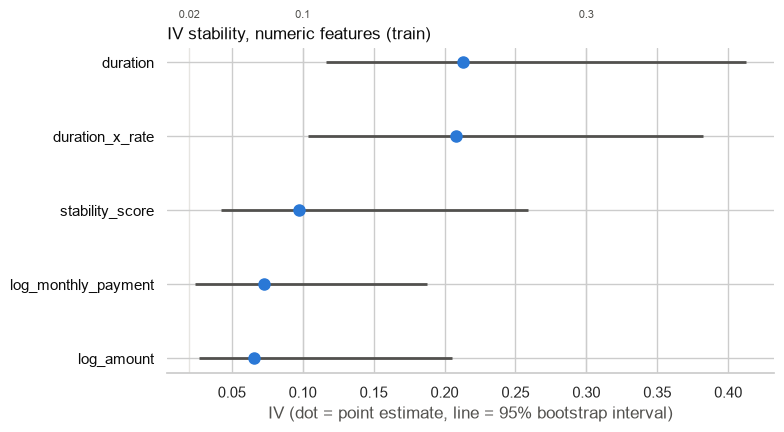

In [17]:
from constants import SEED

def iv_table(x, y, n_bins=5, smooth=0.5):
    """Quantile bin x, then return counts, bad rate, WoE and IV contribution per bin."""
    bins = pd.qcut(x, q=n_bins, duplicates="drop")
    counts = pd.crosstab(bins, y).reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["good", "bad"]
    out = counts.copy()
    out["bad_rate"] = counts["bad"] / (counts["good"] + counts["bad"])
    smoothed = counts + smooth                                   # avoids ln(0) in empty cells
    pct_good = smoothed["good"] / smoothed["good"].sum()
    pct_bad = smoothed["bad"] / smoothed["bad"].sum()
    out["woe"] = np.log(pct_good / pct_bad)
    out["iv_term"] = (pct_good - pct_bad) * out["woe"]
    return out

tables = {col: iv_table(X[col], y) for col in NUMERIC}
point_iv = pd.Series({col: t["iv_term"].sum() for col, t in tables.items()}, name="point_iv")

for col, t in tables.items():
    print(f"\n{col}  (IV = {t['iv_term'].sum():.3f})")
    display(t.round(3))



def iv_fast(x, y, n_bins=5, smooth=0.5):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)[1:-1]))
    bin_id = np.searchsorted(edges, x, side="left")
    k = len(edges) + 1
    good = np.bincount(bin_id[y == 0], minlength=k)
    bad = np.bincount(bin_id[y == 1], minlength=k)
    keep = (good + bad) > 0
    good, bad = good[keep] + smooth, bad[keep] + smooth
    pct_good, pct_bad = good / good.sum(), bad / bad.sum()
    return np.sum((pct_good - pct_bad) * np.log(pct_good / pct_bad))

# check it agrees with the pandas version before trusting it
for col in NUMERIC:
    assert np.isclose(iv_fast(X[col].to_numpy(), y.to_numpy()), point_iv[col]), col

n_boot = 500
rng = np.random.default_rng(SEED)
Xv, yv = X[NUMERIC].to_numpy(), y.to_numpy()
n = len(yv)

boot = np.empty((n_boot, len(NUMERIC)))
for b in range(n_boot):
    pick = rng.integers(0, n, size=n)
    for j in range(len(NUMERIC)):
        boot[b, j] = iv_fast(Xv[pick, j], yv[pick])

summary = pd.DataFrame({
    "point_iv": point_iv,
    "boot_median": np.median(boot, axis=0),
    "ci_low": np.percentile(boot, 2.5, axis=0),
    "ci_high": np.percentile(boot, 97.5, axis=0),
}, index=NUMERIC).sort_values("point_iv", ascending=False)
display(summary.round(3))


order = summary.sort_values("point_iv").index
ypos = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(ypos, summary.loc[order, "ci_low"], summary.loc[order, "ci_high"],
          color=MUTED, linewidth=2)
ax.plot(summary.loc[order, "point_iv"], ypos, "o", color=GOOD, markersize=8)
for cutoff in (0.02, 0.1, 0.3):
    ax.axvline(cutoff, color=GRID, linewidth=1, zorder=0)
    ax.text(cutoff, len(order) - 0.4, f"{cutoff}", color=MUTED, fontsize=8, ha="center")
ax.set_yticks(ypos)
ax.set_yticklabels(order, color=INK)
ax.set_xlabel("IV (dot = point estimate, line = 95% bootstrap interval)", color=MUTED)
ax.set_title("IV stability, numeric features (train)", loc="left", color=INK)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Notes:
1. The vertical bands represent the standard cutoffs for the IV: above 0.3 is strong, above 0.1 is medium and lower than that is weak.
2. Looking at our CIs, `duration` and `duration_x_rate` are medium to strong predictors and will likely improve models.
3. `stability_score` point estimate sits right at the threshold for medium with a larger part of the interval in the medium range. The rest are all weak to medium predictors.

### Categorical variables
To study the categorical (and ordinal) variables, we:\
1. Tabulate the bad rate percetange per category
2. Find the IV for each variable. Once again, due to the limited sample, we bootstrap and attain the CIs.

In [18]:
def bad_rate_table(col, sort_by_rate=False):
    t = y.groupby(X[col]).agg(n="size", bads="sum")
    t["bad_rate"] = t["bads"] / t["n"]
    return t.sort_values("bad_rate", ascending=False) if sort_by_rate else t.sort_index()

print(f"Overall train bad rate: {y.mean():.3f}")

groups_to_show = [
    ("NOMINAL CATEGORICAL (sorted by bad rate)", CATEGORICAL, True),
    ("ORDINAL (sorted by level)", ORDINAL, False),
    ("BINARY", BINARY, False),
]
for title, cols, by_rate in groups_to_show:
    print(f"\n{'=' * 8} {title} {'=' * 8}")
    for col in cols:
        print(f"\n{col}")
        display(bad_rate_table(col, sort_by_rate=by_rate).round(3))

Overall train bad rate: 0.300

======== NOMINAL CATEGORICAL (sorted by bad rate) ========

checking


,n,bads,bad_rate
checking,,,
<0,219,105,0.479
0-200,214,84,0.393
>=200,51,13,0.255
none,316,38,0.120



savings


,n,bads,bad_rate
savings,,,
<100,475,173,0.364
100-500,90,30,0.333
unknown/none,144,24,0.167
500-1000,50,8,0.160
>=1000,41,5,0.122



history


,n,bads,bad_rate
history,,,
none/all paid,31,19,0.613
all paid (this bank),41,22,0.537
existing paid,416,134,0.322
past delay,72,23,0.319
critical,240,42,0.175


... (20 outputs left out)


has_coapplicant


,n,bads,bad_rate
has_coapplicant,,,
0,766,225,0.294
1,34,15,0.441



thin_buffer


,n,bads,bad_rate
thin_buffer,,,
0,625,151,0.242
1,175,89,0.509


Notes:
1. For the categorical variables, there are clear categories where the bad rate is much higher. This is especially visible in `checking`, `housing`, `savings` and `purpose_type`. 
2. For the ordinal variables, the expected ordering is maintained in all except two: `employment_level` (bad rate does not fall steadily with longer employment) and `job_level` (the highest-skilled group defaults more, about 35%, than the two middle groups, about 29%)
3. For the binary variables, there is clear separation, especially in `thin_buffer` which is likely to be a strong predictor.

,group,point_iv,boot_median,ci_low,ci_high
checking,categorical,0.609,0.623,0.413,0.878
history,categorical,0.262,0.275,0.151,0.460
thin_buffer,binary,0.255,0.252,0.130,0.438
asset_score,ordinal,0.228,0.239,0.115,0.416
savings,categorical,0.214,0.236,0.118,0.414
property_level,ordinal,0.145,0.160,0.062,0.327
employment_level,ordinal,0.124,0.140,0.058,0.271
other_plans,categorical,0.091,0.095,0.025,0.208
housing,categorical,0.089,0.091,0.024,0.202
purpose_type,categorical,0.074,0.086,0.026,0.201


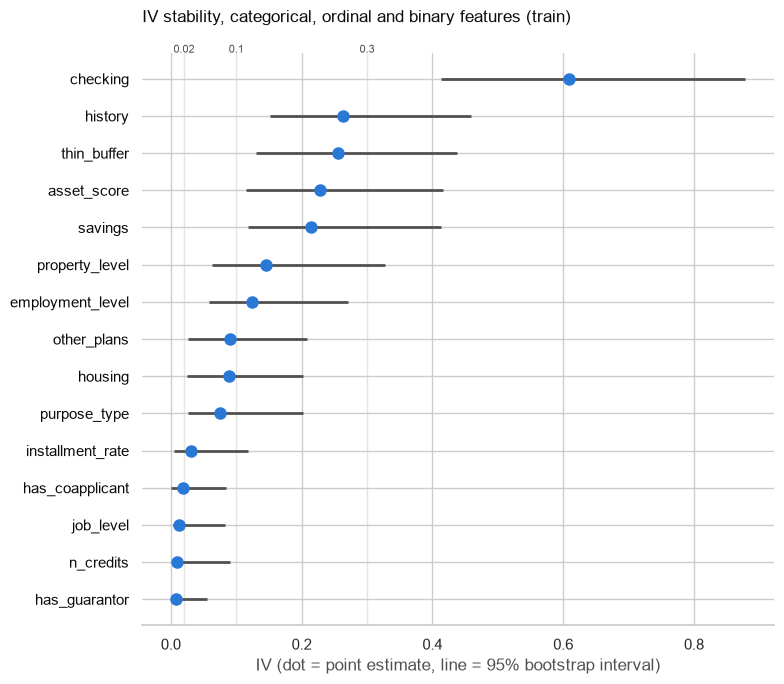

In [19]:
CAT_ALL = CATEGORICAL + ORDINAL + BINARY
yv = y.to_numpy()
n = len(yv)

# one integer id per (level, class) cell: level code * 2 + y, built once
cell, n_levels = {}, {}
for col in CAT_ALL:
    codes, uniques = pd.factorize(X[col])
    cell[col] = codes * 2 + yv
    n_levels[col] = len(uniques)

def iv_from_cells(cell_ids, k, smooth=0.5):
    joint = np.bincount(cell_ids, minlength=2 * k).reshape(k, 2)   # columns: good, bad
    joint = joint[joint.sum(axis=1) > 0] + smooth                   # drop empty levels, smooth the rest
    pct_good = joint[:, 0] / joint[:, 0].sum()
    pct_bad = joint[:, 1] / joint[:, 1].sum()
    return np.sum((pct_good - pct_bad) * np.log(pct_good / pct_bad))

# point estimates
cat_point = pd.Series({c: iv_from_cells(cell[c], n_levels[c]) for c in CAT_ALL})

# bootstrap
n_boot = 500
rng = np.random.default_rng(SEED)
cat_boot = np.empty((n_boot, len(CAT_ALL)))
for b in range(n_boot):
    pick = rng.integers(0, n, size=n)                               # rows drawn with replacement
    for j, c in enumerate(CAT_ALL):
        cat_boot[b, j] = iv_from_cells(cell[c][pick], n_levels[c])

group_of = {**{c: "categorical" for c in CATEGORICAL},
            **{c: "ordinal" for c in ORDINAL},
            **{c: "binary" for c in BINARY}}
cat_summary = pd.DataFrame({
    "group": pd.Series(group_of),
    "point_iv": cat_point,
    "boot_median": np.median(cat_boot, axis=0),
    "ci_low": np.percentile(cat_boot, 2.5, axis=0),
    "ci_high": np.percentile(cat_boot, 97.5, axis=0),
}, index=CAT_ALL).sort_values("point_iv", ascending=False)
display(cat_summary.round(3))

# plot
order = cat_summary.sort_values("point_iv").index
ypos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 7))
ax.hlines(ypos, cat_summary.loc[order, "ci_low"], cat_summary.loc[order, "ci_high"],
          color=MUTED, linewidth=2)
ax.plot(cat_summary.loc[order, "point_iv"], ypos, "o", color=GOOD, markersize=8)
for cutoff in (0.02, 0.1, 0.3):
    ax.axvline(cutoff, color=GRID, linewidth=1, zorder=0)
    ax.text(cutoff, len(order) - 0.3, f"{cutoff}", color=MUTED, fontsize=8, ha="center")
ax.set_yticks(ypos)
ax.set_yticklabels(order, color=INK)
ax.set_xlabel("IV (dot = point estimate, line = 95% bootstrap interval)", color=MUTED)
ax.set_title("IV stability, categorical, ordinal and binary features (train)",
             loc="left", color=INK, pad=22)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Notes:
1. `checking` has an IV of 0.6 and is most likely the top expected predictor in the models to follow.
2. Several other features, most of which are engineered are also in the medium to strong range and will likely feature.
3. The last few in the graph have point estimates near 0. These are not dropped at this point but are not expected to have any signficant impact.

# Part 3 — Model code
The first line of each code cell in this section, `%%writefile <file>`, saves the cell's code to that file so that later cells can import it. It is not part of the code itself.

In [20]:
import os

os.makedirs("models", exist_ok=True)
open("models/__init__.py", "a").close()  # makes models/ an importable package

### `models/common.py`
Shared workflow used by every model: preprocessing, tuning on training data only, cost-optimal threshold, evaluation, plots, model comparison, SHAP and fairness.

In [21]:
%%writefile models/common.py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from constants import CV, SEED, NUMERIC, ORDINAL, CATEGORICAL, BINARY, SHAP_GROUPS

COST_FN, COST_FP = 5, 1  # german.doc cost matrix: bad classed good = 5, good classed bad = 1
THRESHOLDS = np.linspace(0.01, 0.99, 99)

def preprocessor():
    """Scale numeric and ordinal, one-hot categorical, pass binary 0/1 through. Fit on train only, via the pipeline."""
    # ordinal levels are scaled so regularisation penalises every coefficient on the same footing
    return ColumnTransformer(
        [("num", StandardScaler(), NUMERIC + ORDINAL),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
         ("bin", "passthrough", BINARY)],
        verbose_feature_names_out=False)


def cost(y, pred): # Counts the mistakes and charges 5 for each bad borrower approved and 1 for each good borrower rejected.
    _, fp, fn, _ = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return COST_FN * fn + COST_FP * fp

#Turns predicted probabilities into approve/reject decisions at threshold t, then computes AUC, precision, recall, F1, the rejection rate and the cost per applicant.
def metrics(y, proba, t):
    pred = (proba >= t).astype(int)
    return {"auc": roc_auc_score(y, proba), "avg_precision": average_precision_score(y, proba),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "reject_rate": pred.mean(), "cost_per_applicant": cost(y, pred) / len(y)}

# Main training workflow. Uses TRAINING DATA ONLY: tunes hyperparameters and the threshold, never touches the test set.
def fit(name, pipe, grid, data, scoring="roc_auc"):
    search = GridSearchCV(pipe, grid, scoring=scoring, cv=CV, n_jobs=-1)
    search.fit(data["X_train"], data["y_train"])
    model = search.best_estimator_ # Find the best hyperparameters for the model using cross-validation and grid search

    # Out-of-fold predictions: every training row is scored by a model that never saw it, giving an honest CV view
    oof = cross_val_predict(clone(model), data["X_train"], data["y_train"], cv=CV, method="predict_proba")[:, 1]
    # Pick the best threshold on out-of-fold train predictions so the test set is never used for tuning
    threshold = THRESHOLDS[np.argmin([cost(data["y_train"], oof >= t) for t in THRESHOLDS])]

    return {"name": name, "model": model, "best_params": search.best_params_,
            "cv_auc": search.best_score_, "cv_auc_std": search.cv_results_["std_test_score"][search.best_index_],
            "threshold": threshold, "oof": oof, "y_oof": data["y_train"].to_numpy()}

# FINAL EVALUATION: scores the frozen model on the TEST SET. Call once, after all modelling choices are made.
def evaluate(res, data):
    res["proba"] = res["model"].predict_proba(data["X_test"])[:, 1] # Get the predicted probabilities for the TEST SET
    res["y_test"] = data["y_test"].to_numpy()
    return res

# Returns (true labels, predicted probabilities) for either the CV out-of-fold predictions or the test set.
def _pick(res, on):
    if on == "cv":
        return res["y_oof"], res["oof"]
    if "proba" not in res:
        raise RuntimeError(f"{res['name']}: test set not evaluated yet - run common.evaluate() in the Final Evaluation section")
    return res["y_test"], res["proba"]

# Draws 4 charts for 1 model: ROC, precision-recall, the confusion matrix and cost vs threshold. on="cv" (default) or "test".
def report(res, on="cv"):
    y, p = _pick(res, on)
    t = res["threshold"]
    label = "CV out-of-fold (train)" if on == "cv" else "TEST SET"
    print(f"{res['name']} - {label}\nBest params: {res['best_params']}\n"
          f"CV AUC: {res['cv_auc']:.3f} ± {res['cv_auc_std']:.3f}")
    display(pd.DataFrame({"t=0.50": metrics(y, p, 0.5), f"t={t:.2f} (cost-opt)": metrics(y, p, t)}).T.round(3))

    fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr)
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[0].set(title=f"ROC ({label})", xlabel="FPR", ylabel="TPR")
    prec, rec, _ = precision_recall_curve(y, p)
    ax[1].plot(rec, prec)
    ax[1].axhline(y.mean(), color="k", ls="--", lw=0.8)
    ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision")
    ConfusionMatrixDisplay.from_predictions(y, (p >= t).astype(int), display_labels=["No", "Yes"],
                                            ax=ax[2], colorbar=False)
    ax[2].set_title(f"Confusion matrix (t={t:.2f})")
    ax[3].plot(THRESHOLDS, [cost(y, p >= th) / len(y) for th in THRESHOLDS])
    ax[3].axvline(t, color="r", ls="--", label="chosen (CV)")
    ax[3].axvline(0.5, color="k", ls=":", label="0.5")
    ax[3].set(title="Expected cost vs threshold", xlabel="Threshold", ylabel="Cost per applicant")
    ax[3].legend()
    plt.tight_layout()
    plt.show()

# Puts every model in 1 table next to 2 baselines ("approve everyone" and "reject everyone"), plus an ROC chart with all models overlaid.
# Use on="cv" for model selection; on="test" only in the Final Evaluation section.
def compare(results, on="cv"):
    results = list(results)
    rows = {r["name"]: {"cv_auc": r["cv_auc"], "cv_auc_std": r["cv_auc_std"], "threshold": r["threshold"],
                        **metrics(*_pick(r, on), r["threshold"])} for r in results}
    y = _pick(results[0], on)[0]
    rows["Approve all"] = {"cost_per_applicant": COST_FN * y.mean(), "reject_rate": 0.0}
    rows["Reject all"] = {"cost_per_applicant": COST_FP * (1 - y.mean()), "reject_rate": 1.0}
    print("CV out-of-fold (train)" if on == "cv" else "TEST SET")
    display(pd.DataFrame(rows).T.round(3))

    for r in results:
        yr, pr = _pick(r, on)
        fpr, tpr, _ = roc_curve(yr, pr)
        plt.plot(fpr, tpr, label=f"{r['name']} (AUC={roc_auc_score(yr, pr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=0.8)
    plt.gca().set(title=f"ROC comparison ({on})", xlabel="FPR", ylabel="TPR")
    plt.legend()
    plt.show()


def _original(name):
    for c in CATEGORICAL:
        if name.startswith(c + "_"):
            return c
    return name


# SHAP plots: which features matter overall + a breakdown of why the riskiest applicant was flagged.
def explain(res, data, max_display=15, bg_size=800, merge=SHAP_GROUPS):
    import shap

    _, proba = _pick(res, "test")
    pre, clf = res["model"][:-1], res["model"][-1]
    names = pre.get_feature_names_out()
    X_bg = pd.DataFrame(pre.transform(data["X_train"]), columns=names)
    X_te = pd.DataFrame(pre.transform(data["X_test"]), columns=names)
    bg = shap.sample(X_bg, bg_size, random_state=SEED)
    masker = shap.maskers.Independent(bg, max_samples=bg_size)
    try:
        explainer = shap.Explainer(clf, masker)
    except Exception:
        explainer = shap.Explainer(lambda x: clf.predict_proba(x)[:, 1], masker)
    sv = explainer(X_te)
    if sv.values.ndim == 3:
        sv = sv[:, :, 1]

    sv.data = sv.data.copy()
    for j, n in enumerate(names):
        if n in data["X_test"].columns:
            sv.data[:, j] = data["X_test"][n].to_numpy()

    owner = pd.Series([_original(n) for n in names], index=names)
    if merge:
        owner = owner.replace(merge)
    grouped = pd.DataFrame(sv.values, columns=names).T.groupby(owner).sum().T
    imp = grouped.abs().mean().sort_values().tail(max_display)
    plt.figure(figsize=(8, 0.35 * len(imp) + 1))
    plt.barh(imp.index, imp.values)
    plt.title("Mean absolute SHAP value per feature")
    plt.xlabel("Mean |SHAP|")
    plt.tight_layout()
    plt.show()

    # this method is compatible with all the models used; adaboost and ANN use the fallback
    # however while most including xgboost use log odds, some use probability. therefore rankings are 
    # comparable but raw values are not.

    #given the concerns of multicollinearity and the dummy variables, the grouped bar chart is better for ranking
    # the beeswarm plot that follows gives more insight using each category

    # the column groups are only used for the grouped bar chart, not the plots that come after
    # even the categorical dummy collapsing does not hold up after for the beeswarm plot
    shap.plots.beeswarm(sv, max_display=max_display)


    cases = [("Highest risk", int(np.argmax(proba))),
             ("Closest to the decision threshold", int(np.argmin(np.abs(proba - res["threshold"]))))]
    for label, i in cases:
        print(f"{label}: P(default) = {proba[i]:.2f}")
        shap.plots.waterfall(sv[i], max_display=max_display)
    return sv

# Approval rates and error rates for each group (sex, foreign worker,age_less_30).
def fairness(res, data):
    g = data["groups_test"].reset_index(drop=True)
    y, p = _pick(res, "test")
    pred = (p >= res["threshold"]).astype(int)
    rows = []
    for attr in g.columns:
        for val, idx in g.groupby(attr).groups.items():
            yi, pi = y[idx], pred[idx]
            rows.append({"attribute": attr, "group": val, "n": len(idx), "default_rate": yi.mean(),
                         "approval_rate": 1 - pi.mean(),
                         "tpr (bad caught)": pi[yi == 1].mean() if yi.sum() else np.nan,
                         "fpr (good rejected)": pi[yi == 0].mean() if (yi == 0).sum() else np.nan,
                         "auc": roc_auc_score(yi, p[idx]) if 0 < yi.sum() < len(yi) else np.nan})
    out = pd.DataFrame(rows).set_index(["attribute", "group"])
    # disparate impact: group approval rate / best-treated group's approval rate (< 0.8 is the usual red flag)
    out["approval_ratio"] = out["approval_rate"] / out.groupby(level=0)["approval_rate"].transform("max")
    display(out.round(3))
    return out


Writing models/common.py


### `models/logistic_regression.py`
Logistic regression (required by the brief).

In [22]:
%%writefile models/logistic_regression.py
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from constants import SEED
from models import common

NAME = "Logistic Regression"
# Hyperparameter grid for logistic regression: regularization strength (C), l1_ratio for elastic net, and class weight.
GRID = {
    "clf__C": np.logspace(-3, 2, 11), # Regularisation strength (inverse of regularisation parameter). Smaller values specify stronger regularization.
    "clf__l1_ratio": [0.0, 0.2, 0.5, 0.8, 1.0],
    "clf__class_weight": [None, "balanced"],  # None = no class weighting, "balanced" = inverse frequency of classes (Bad is weighted more heavily)
}


def build():
    return Pipeline([("pre", common.preprocessor()),
                     ("clf", LogisticRegression(solver="saga", max_iter=5000, random_state=SEED))]) #saga solver supports L1, L2, and elastic net regularization. 


def run(data):
    return common.fit(NAME, build(), GRID, data)


def report(res, top=15):
    common.report(res)  # CV view only; test-set results come from the Final Evaluation section


Writing models/logistic_regression.py


### `models/random_forest.py`
Random forest (required by the brief; the primary model).

In [23]:
%%writefile models/random_forest.py
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from constants import SEED
from models import common

NAME = "Random Forest"
# n_estimators is fixed (more trees never hurts accuracy, only speed); tune how complex each tree is instead.
GRID = {
    "clf__max_depth": [2,3,4], 
    "clf__min_samples_leaf": [3,5,7],
    "clf__max_features": [0.1, "sqrt", 0.3], 
    "clf__class_weight": [None, "balanced_subsample"],
}


def build():
    return Pipeline([("pre", common.preprocessor()),
                     ("clf", RandomForestClassifier(n_estimators=500, n_jobs=1,  # GridSearchCV already parallelises
                                                    random_state=SEED))])


def run(data):  # training data only - the test set is evaluated once in master.ipynb's Final Evaluation section
    return common.fit(NAME, build(), GRID, data)


def report(res, top=15):
    common.report(res)  # CV view only

Writing models/random_forest.py


### `models/adaboost.py`
AdaBoost (required by the brief).

In [24]:
%%writefile models/adaboost.py
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from constants import SEED
from models import common

NAME = "AdaBoost"
# AdaBoost = many weak trees fitted in sequence, each focusing on the applicants the previous ones got wrong.
GRID = {
    "clf__n_estimators": [50, 100, 200, 400],
    "clf__learning_rate": [0.1, 0.3, 0.5, 1.0],                 # shrinks each tree's vote; lower needs more trees
    "clf__estimator__max_depth": [1, 2, 3],                     # 1 = stumps (no interactions), the classic weak learner
    "clf__estimator__class_weight": [None, "balanced"],         # start with bad borrowers weighted up
}


def build():
    return Pipeline([("pre", common.preprocessor()),
                     ("clf", AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=SEED),
                                                random_state=SEED))])


def run(data):  # training data only - the test set is evaluated once in master.ipynb's Final Evaluation section
    return common.fit(NAME, build(), GRID, data)


def report(res, top=15):
    common.report(res)  # CV view only


Writing models/adaboost.py


### `models/xgboost_model.py`
XGBoost (additional model).

In [25]:
%%writefile models/xgboost_model.py
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from constants import SEED
from models import common

NAME = "XGBoost"
# Small data (800 training rows) -> favour shallow trees, slow learning and subsampling to limit overfitting.
GRID = {
    "clf__n_estimators": [150, 300],
    "clf__learning_rate": [0.01, 0.03],      # small steps + more trees generalise better on small data
    "clf__max_depth": [2, 3,4],             # tree depth = order of feature interactions allowed
    "clf__min_child_weight": [1, 3,5],         # min (hessian) weight per leaf; higher = more conservative splits
    "clf__colsample_bytree": [0.3, 0.5],     # fraction of features sampled per tree (decorrelates trees)
    "clf__scale_pos_weight": [1, 7 / 3],     # 7/3 = good/bad ratio, XGBoost's analogue of class_weight="balanced"
}


def build():
    return Pipeline([("pre", common.preprocessor()),
                     ("clf", XGBClassifier(subsample=0.8, reg_lambda=1.0, tree_method="hist",
                                           eval_metric="logloss", n_jobs=1,  # GridSearchCV already parallelises
                                           random_state=SEED))])


def run(data):  # training data only - the test set is evaluated once in master.ipynb's Final Evaluation section
    return common.fit(NAME, build(), GRID, data)


def report(res, top=15):
    common.report(res)  # CV view only


Writing models/xgboost_model.py


### `models/lightGBM.py`
LightGBM (additional model).

In [26]:
%%writefile models/lightGBM.py
"""LightGBM credit-default model using the shared training workflow."""

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

from constants import SEED
from models import common


NAME = "LightGBM"


def build():
    return Pipeline([
        ("pre", common.preprocessor()),
        ("clf", LGBMClassifier(
            objective="binary",
            random_state=SEED,
            n_jobs=1,
            verbosity=-1,
        )),
    ])


# 32 combinations, assessed using the shared 5-fold training-only CV.
GRID = {
    "clf__num_leaves": [3, 7, 15],
    "clf__min_child_samples": [20, 40],
    "clf__learning_rate": [0.03, 0.10],
    "clf__n_estimators": [100, 200],
    "clf__colsample_bytree": [0.5, 1.0],
    "clf__reg_lambda": [0.0, 5.0],
}


def run(data):
    return common.fit(NAME, build(), GRID, data)


def report(res, on="cv"):
    common.report(res, on=on)

Writing models/lightGBM.py


### `models/neural_network.py`
Neural network in TensorFlow/Keras, wrapped as a scikit-learn estimator (additional model).

In [27]:
%%writefile models/neural_network.py
"""ANN (TensorFlow/Keras) wrapped as a scikit-learn estimator, so it plugs into the shared pipeline, grid search and CV.
Overfitting is curbed by dropout, an L2 penalty and early stopping on a validation slice of the training fold."""
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # hide TensorFlow start-up logs (also in GridSearchCV workers)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from constants import SEED
from models import common

NAME = "ANN"

GRID = {"clf__hidden": [(4,), (8,), (16,)],
        "clf__dropout": [0.1, 0.2, 0.3], #share of units randomly switched off each training step
        "clf__l2": [0.01, 0.03, 0.1]} # weight penalty on every dense layer

class KerasMLP(ClassifierMixin, BaseEstimator):
    """Keras network behind the sklearn interface (fit / predict_proba / get_params), so GridSearchCV,
    cross_val_predict and clone treat it like any other classifier."""

    def __init__(self, hidden=(16,), dropout=0.2, l2=1e-3, learning_rate=1e-3, epochs=300, batch_size=32,
                 patience=20, validation_fraction=0.15, random_state=SEED):
        self.hidden = hidden
        self.dropout = dropout
        self.l2 = l2
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.validation_fraction = validation_fraction
        self.random_state = random_state

    def fit(self, X, y):
        import keras  # imported here so each GridSearchCV worker loads TensorFlow itself
        from keras import layers, regularizers

        X, y = np.asarray(X, dtype="float32"), np.asarray(y)
        self.classes_ = np.unique(y)
        keras.utils.set_random_seed(self.random_state)  # reproducible weights, dropout masks and shuffling

        # early stopping watches a slice of THIS training fold only, so the CV fold being scored is never seen
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=self.validation_fraction,
                                                    stratify=y, random_state=self.random_state)
        net = keras.Sequential([keras.Input(shape=(X.shape[1],))])
        for units in self.hidden:
            net.add(layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(self.l2)))
            net.add(layers.Dropout(self.dropout))
        net.add(layers.Dense(1, activation="sigmoid"))
        net.compile(optimizer=keras.optimizers.Adam(self.learning_rate), loss="binary_crossentropy")

        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience, restore_best_weights=True)
        hist = net.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=self.epochs,
                       batch_size=self.batch_size, callbacks=[stop], verbose=0)
        self.model_ = net
        self.loss_curve_ = hist.history["loss"]
        self.val_loss_curve_ = hist.history["val_loss"]
        self.best_epoch_ = int(np.argmin(self.val_loss_curve_)) + 1
        return self

    def predict_proba(self, X):
        p = self.model_.predict(np.asarray(X, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]


def build():
    return Pipeline([("pre", common.preprocessor()), ("clf", KerasMLP())])


def run(data):  # training data only - the test set is evaluated once in master.ipynb's Final Evaluation section
    res = common.fit(NAME, build(), GRID, data)
    model = res["model"]
    res["train_auc"] = roc_auc_score(data["y_train"], model.predict_proba(data["X_train"])[:, 1])  # for the overfitting gap
    res["loss_curve"] = model[-1].loss_curve_
    res["val_loss_curve"] = model[-1].val_loss_curve_
    res["best_epoch"] = model[-1].best_epoch_
    return res


def report(res):
    common.report(res)  # CV view
    gap = res["train_auc"] - res["cv_auc"]
    print(f"Train AUC: {res['train_auc']:.3f} | CV AUC: {res['cv_auc']:.3f} | gap: {gap:.3f}")

    plt.figure(figsize=(5, 3.5))
    plt.plot(res["loss_curve"], label="train")
    plt.plot(res["val_loss_curve"], label="validation")
    plt.axvline(res["best_epoch"] - 1, color="k", ls=":", label=f"early stop (epoch {res['best_epoch']})")
    plt.gca().set(title="Training vs validation loss", xlabel="Epoch", ylabel="Log loss + L2 penalty")
    plt.legend()
    plt.tight_layout()
    plt.show()


Writing models/neural_network.py


# Part 4 — Modelling results, evaluation, explainability and fairness

### Modelling workflow
Each model lives in `models/` and exposes `run(data)` (training data only) and `report(res)` (cross-validated results).
All models share the same train/test split, 5-fold stratified CV and cost matrix (bad classed good = 5, good classed bad = 1).

**Workflow**
1. *Model development* — run, compare and iterate using **CV results only**.
2. *Final evaluation* — once every model is frozen, run that section **once**. Do not go back and tweak models after seeing test results.

In [28]:
%matplotlib inline
from feature_engineering import get_data
from models import common

data = get_data()
results = {}
print({k: v.shape for k, v in data.items()})

{'X_train': (800, 20), 'X_test': (200, 20), 'y_train': (800,), 'y_test': (200,), 'groups_train': (800, 3), 'groups_test': (200, 3)}


## 4.1 Model development (training data / CV only)

## Logistic Regression

Logistic Regression - CV out-of-fold (train)
Best params: {'clf__C': np.float64(0.1), 'clf__class_weight': None, 'clf__l1_ratio': 0.2}
CV AUC: 0.777 ± 0.053


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.776,0.583,0.640,0.371,0.470,0.174,1.006
t=0.17 (cost-opt),0.776,0.583,0.406,0.921,0.564,0.680,0.522


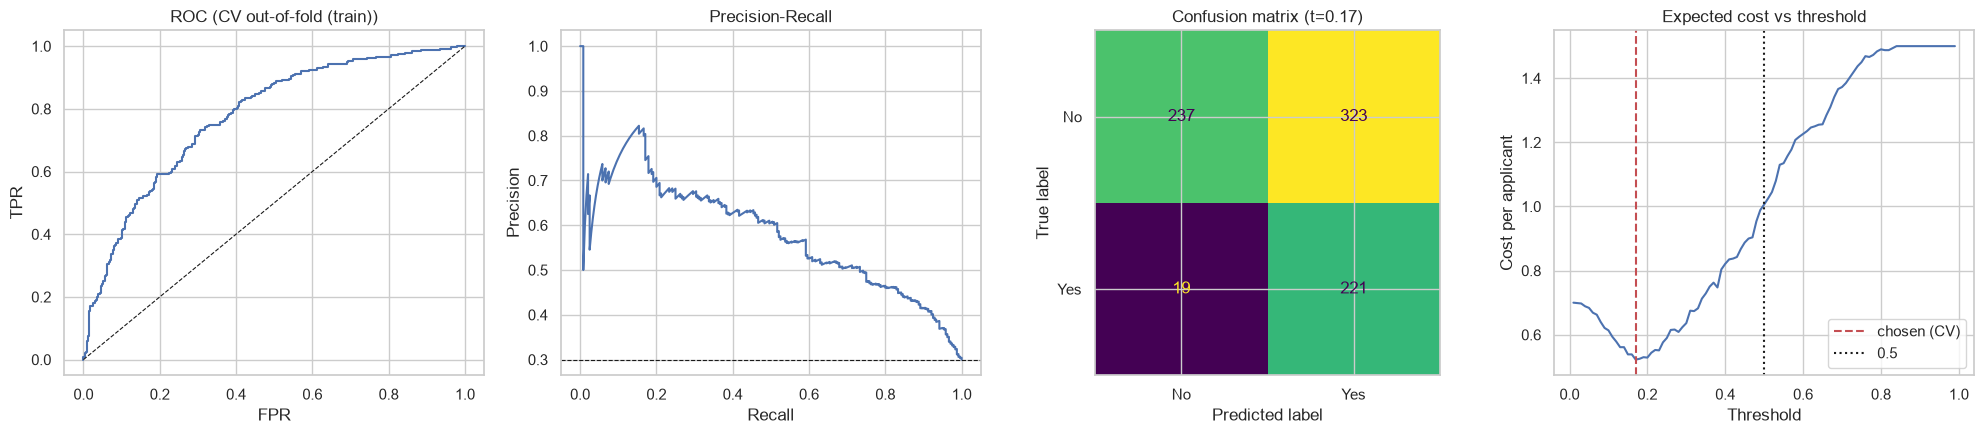

In [29]:
from models import logistic_regression as lr

results["lr"] = lr.run(data)
lr.report(results["lr"])

## Random Forest

Random Forest - CV out-of-fold (train)
Best params: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 4, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}
CV AUC: 0.792 ± 0.047


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.791,0.614,0.532,0.696,0.603,0.392,0.640
t=0.37 (cost-opt),0.791,0.614,0.431,0.900,0.583,0.626,0.506


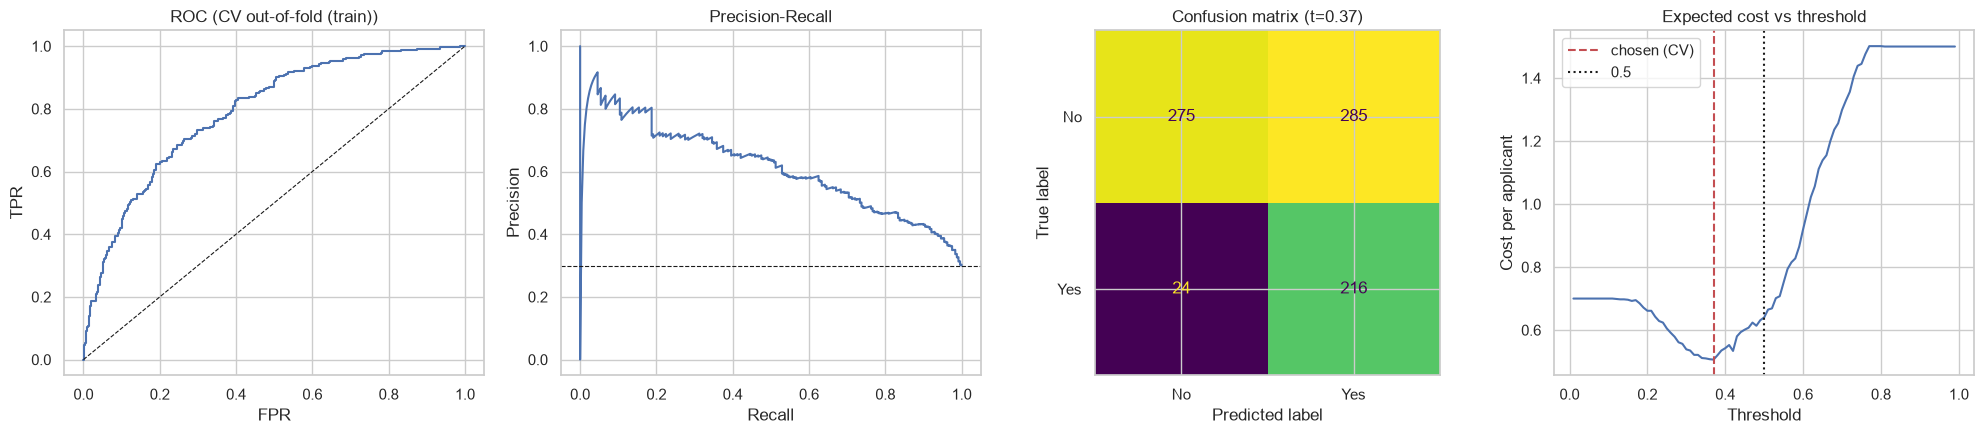

In [30]:
from models import random_forest as rf

results["rf"] = rf.run(data)
rf.report(results["rf"])

## XGBoost

XGBoost - CV out-of-fold (train)
Best params: {'clf__colsample_bytree': 0.3, 'clf__learning_rate': 0.03, 'clf__max_depth': 4, 'clf__min_child_weight': 5, 'clf__n_estimators': 150, 'clf__scale_pos_weight': 2.3333333333333335}
CV AUC: 0.803 ± 0.039


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.8,0.626,0.549,0.675,0.606,0.369,0.654
t=0.26 (cost-opt),0.8,0.626,0.407,0.933,0.567,0.688,0.507


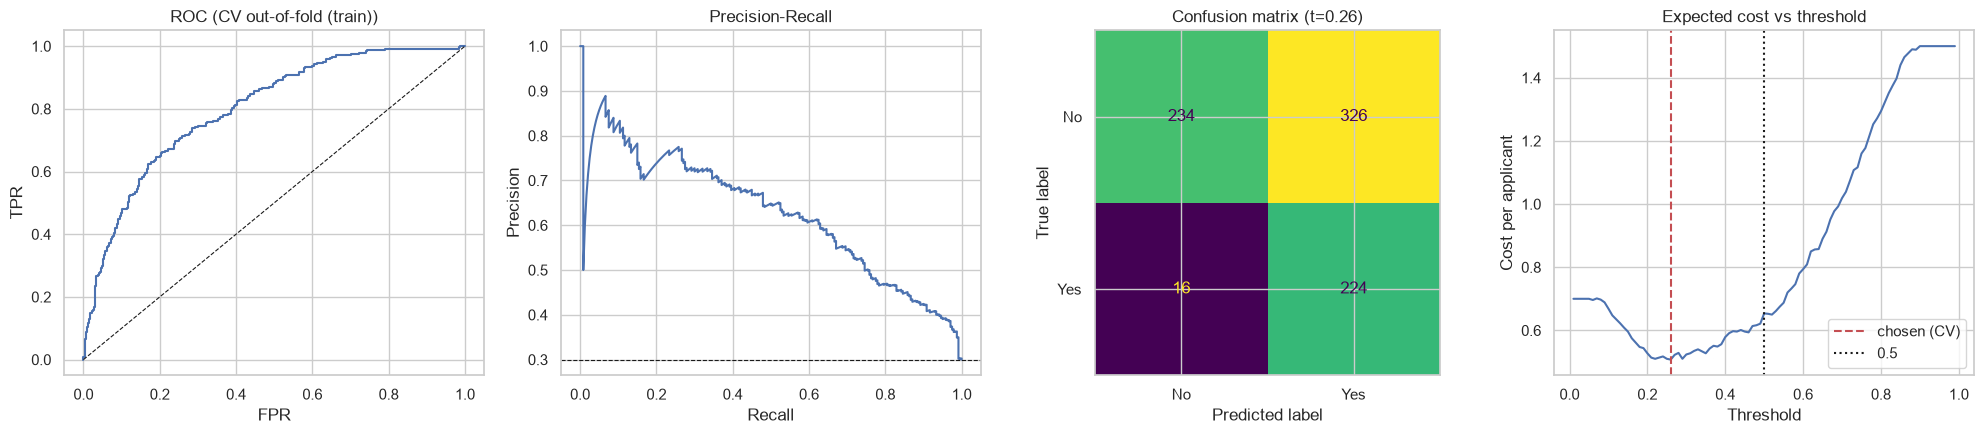

In [31]:
from models import xgboost_model as xgbm

results["xgb"] = xgbm.run(data)
xgbm.report(results["xgb"])

## AdaBoost

AdaBoost - CV out-of-fold (train)
Best params: {'clf__estimator__class_weight': None, 'clf__estimator__max_depth': 1, 'clf__learning_rate': 0.5, 'clf__n_estimators': 200}
CV AUC: 0.784 ± 0.041


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.784,0.597,0.647,0.421,0.510,0.195,0.938
t=0.39 (cost-opt),0.784,0.597,0.407,0.917,0.564,0.675,0.525


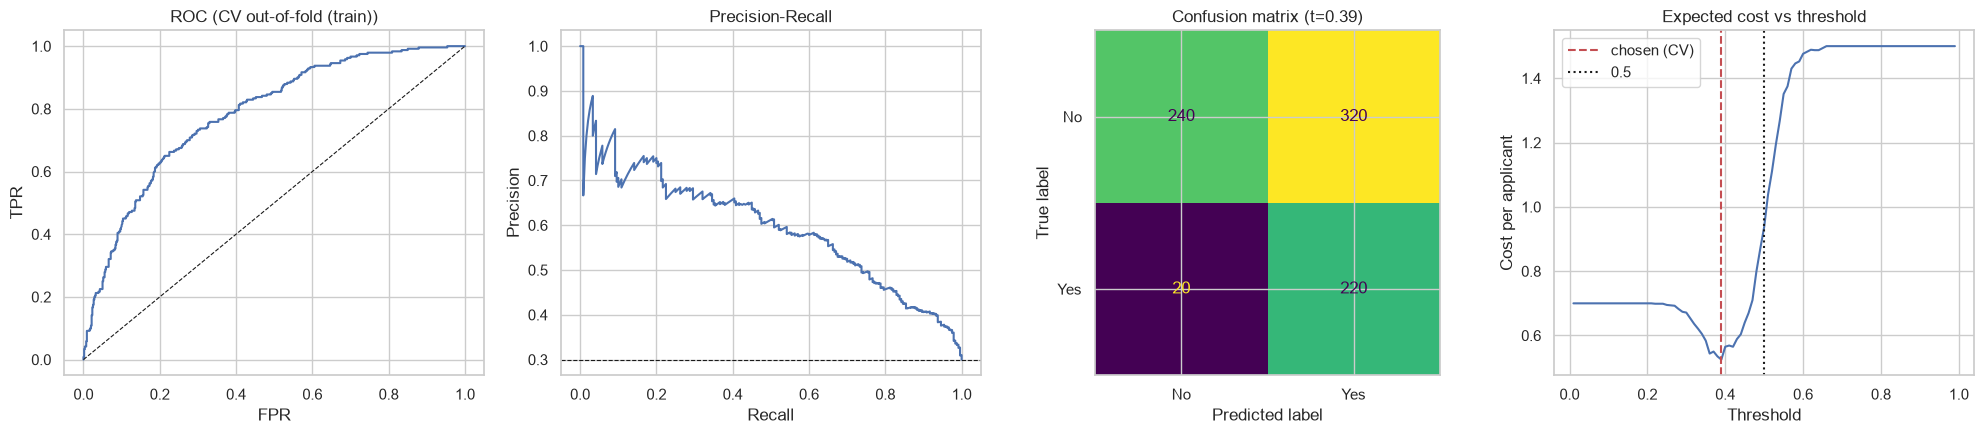

In [32]:
from models import adaboost as ada

results["ada"] = ada.run(data)
ada.report(results["ada"])

## LightGBM

LightGBM - CV out-of-fold (train)
Best params: {'clf__colsample_bytree': 0.5, 'clf__learning_rate': 0.1, 'clf__min_child_samples': 20, 'clf__n_estimators': 100, 'clf__num_leaves': 15, 'clf__reg_lambda': 5.0}
CV AUC: 0.798 ± 0.036


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.796,0.608,0.647,0.458,0.537,0.212,0.888
t=0.10 (cost-opt),0.796,0.608,0.411,0.942,0.572,0.688,0.492


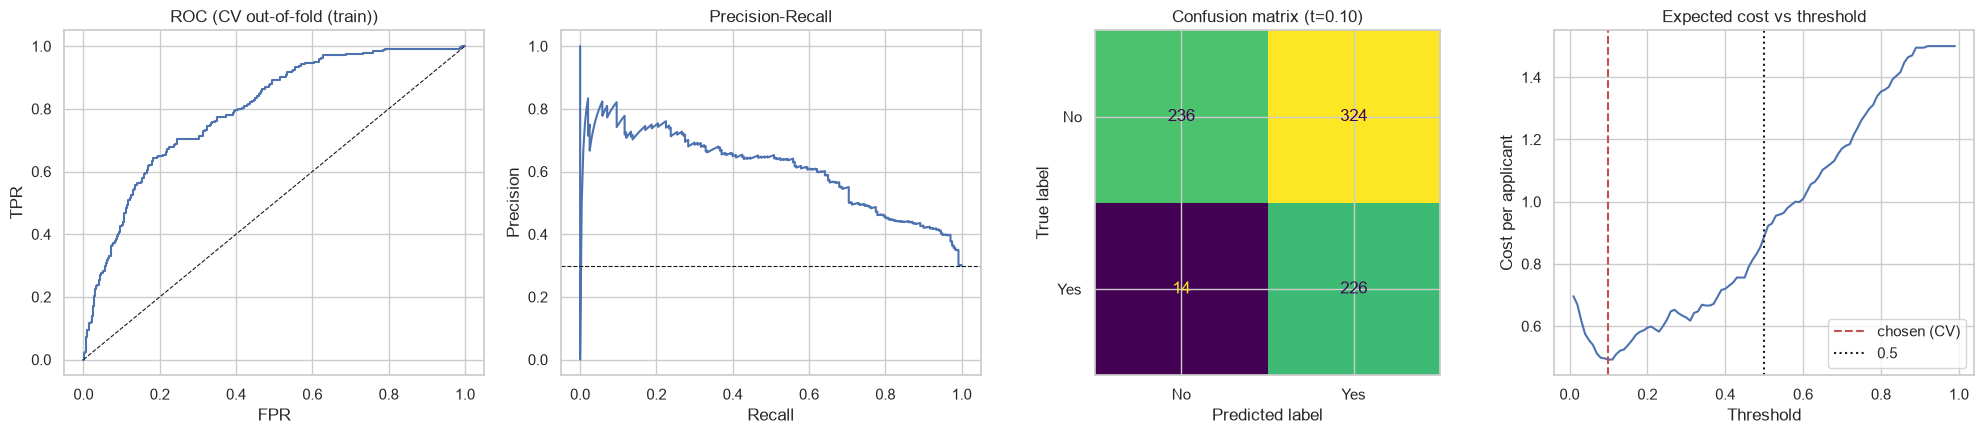

In [33]:
from models import lightGBM as lgbm

results["lgbm"] = lgbm.run(data)
lgbm.report(results["lgbm"])

## Neural Network (ANN)

ANN - CV out-of-fold (train)
Best params: {'clf__dropout': 0.3, 'clf__hidden': (4,), 'clf__l2': 0.01}
CV AUC: 0.783 ± 0.053


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.776,0.589,0.644,0.354,0.457,0.165,1.028
t=0.16 (cost-opt),0.776,0.589,0.403,0.912,0.559,0.679,0.536


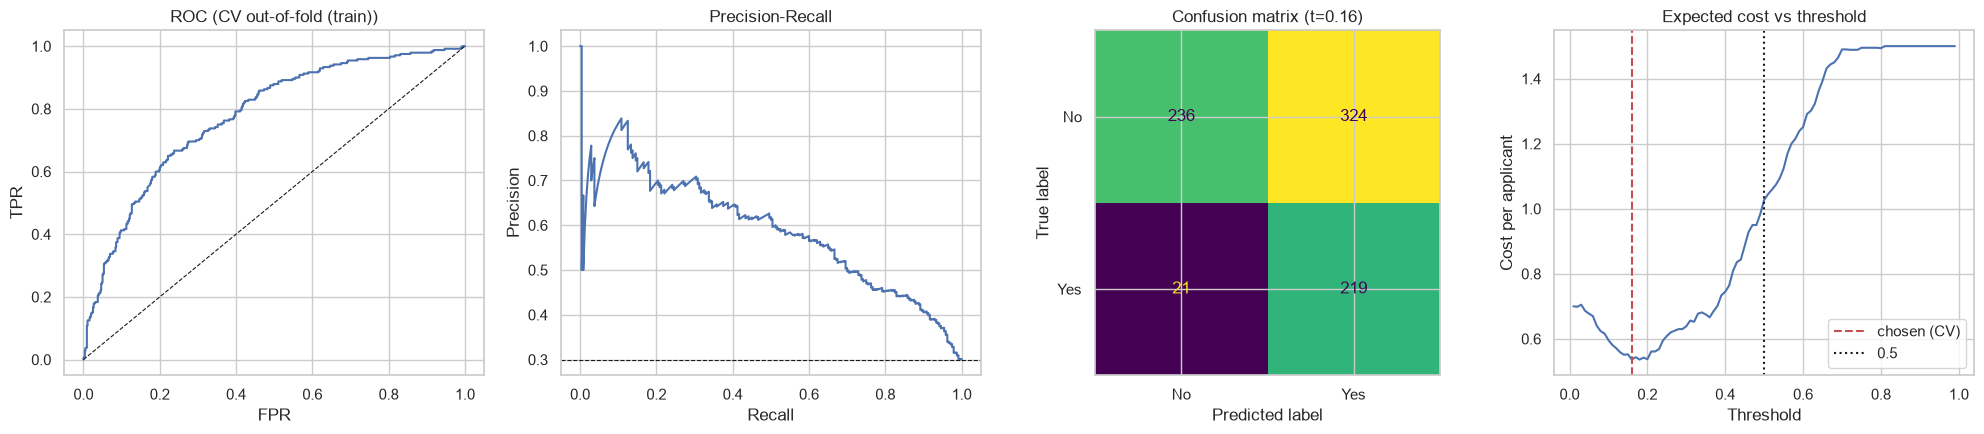

Train AUC: 0.812 | CV AUC: 0.783 | gap: 0.029


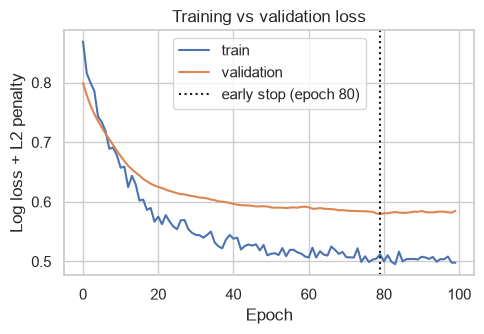

In [34]:
from models import neural_network as ann

results["ann"] = ann.run(data)
ann.report(results["ann"])

## Model selection (CV)
Choose models on these cross-validated numbers, not on test results.

CV out-of-fold (train)


,cv_auc,cv_auc_std,threshold,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
Logistic Regression,0.777,0.053,0.17,0.776,0.583,0.406,0.921,0.564,0.680,0.522
Random Forest,0.792,0.047,0.37,0.791,0.614,0.431,0.900,0.583,0.626,0.506
XGBoost,0.803,0.039,0.26,0.800,0.626,0.407,0.933,0.567,0.688,0.507
AdaBoost,0.784,0.041,0.39,0.784,0.597,0.407,0.917,0.564,0.675,0.525
LightGBM,0.798,0.036,0.10,0.796,0.608,0.411,0.942,0.572,0.688,0.492
ANN,0.783,0.053,0.16,0.776,0.589,0.403,0.912,0.559,0.679,0.536
Approve all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,1.500
Reject all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.700


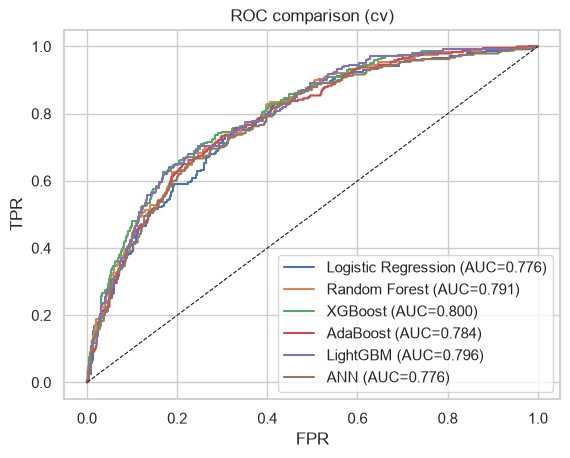

In [35]:
common.compare(results.values(), on="cv")

On the cross-validated results, the models are close: every CV AUC lies within roughly one fold standard deviation of the others, and the boosters and random forest lead logistic regression and the ANN by a small margin.

- **AUC (threshold-independent ranking quality):** `XGBoost` is highest (0.803 ± 0.039), followed by `LightGBM` (0.798 ± 0.036) and `Random Forest` (0.792 ± 0.047). All three are within one fold standard deviation of each other.
- **Cost per applicant:** `LightGBM` is lowest (0.492), with `Random Forest` (0.506) and `XGBoost` (0.507) effectively tied. These cost figures are slightly optimistic, because each threshold is chosen on the same out-of-fold predictions it is scored on, and the gaps between them are small relative to that noise.
- **Precision, F1 and reject rate (at each model's cost-optimal threshold):** `Random Forest` is best on all three: precision 0.431, F1 0.583 and reject rate 0.626.

`Random Forest` is chosen as the primary model. Because the models are statistically tied on AUC and cost, the deciding factor is precision: among applicants the model flags as risky, `Random Forest` has the highest share who really are bad borrowers, so it wrongly turns away the fewest good customers (lowest reject rate) while matching the best models on cost. It is also built from shallow trees (depth 4), which keeps it comparatively interpretable. This choice was finalised after the test results had been seen, so it rests on the CV metrics above rather than on test performance. Test metrics are still reported for all models below, but SHAP and the fairness analysis are carried out on `Random Forest` only.

## 4.2 Final evaluation (run ONCE, after all models are frozen)
Everything below uses the held-out test set.

Logistic Regression - TEST SET
Best params: {'clf__C': np.float64(0.1), 'clf__class_weight': None, 'clf__l1_ratio': 0.2}
CV AUC: 0.777 ± 0.053


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.77,0.604,0.600,0.400,0.480,0.200,0.980
t=0.17 (cost-opt),0.77,0.604,0.376,0.883,0.527,0.705,0.615


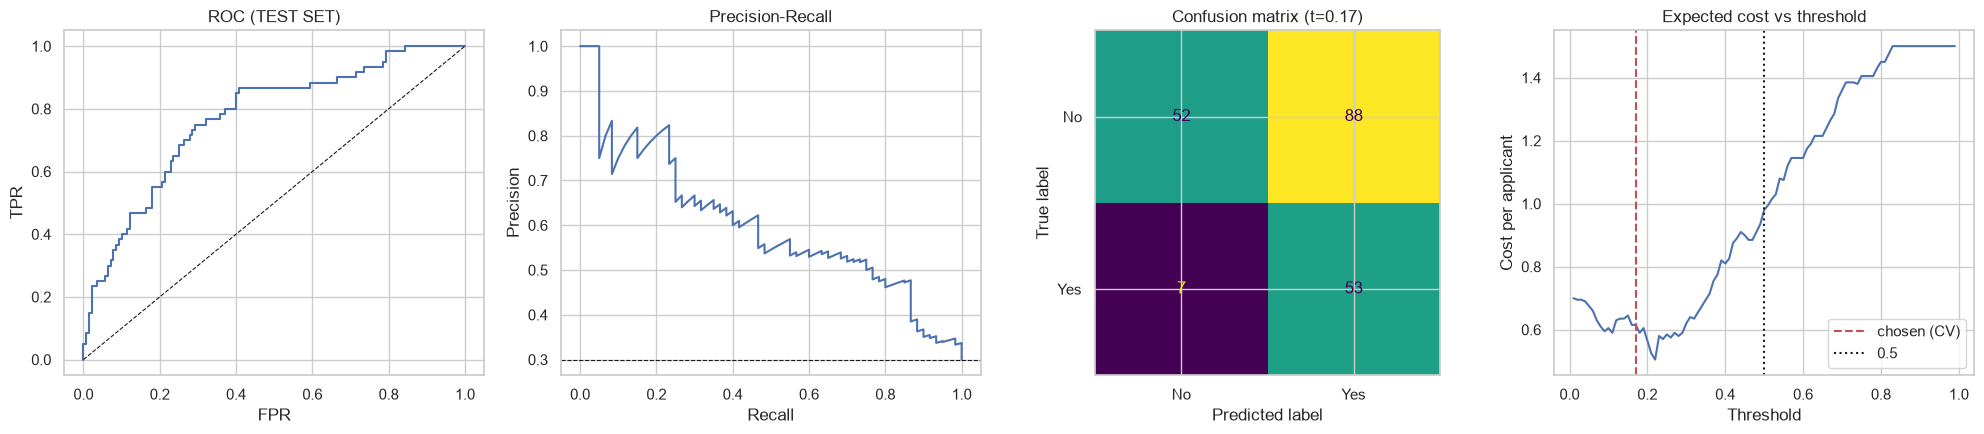

Random Forest - TEST SET
Best params: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 4, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}
CV AUC: 0.792 ± 0.047


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.792,0.64,0.561,0.767,0.648,0.41,0.53
t=0.37 (cost-opt),0.792,0.64,0.398,0.850,0.543,0.64,0.61


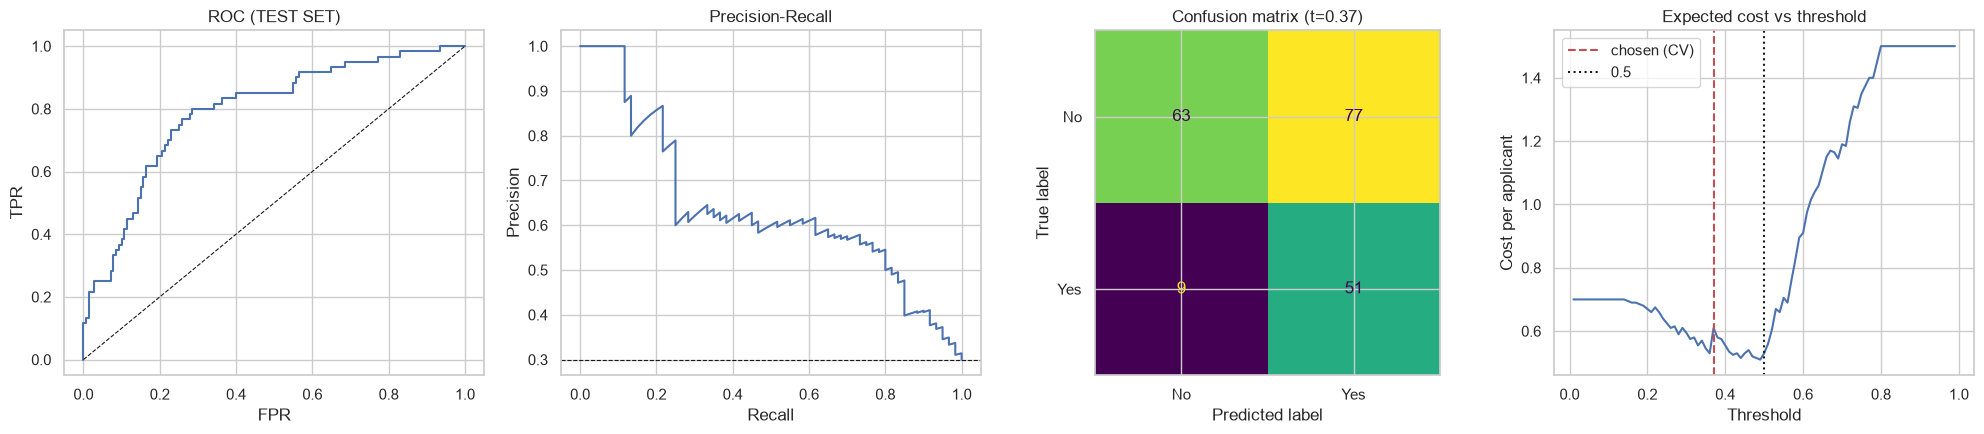

XGBoost - TEST SET
Best params: {'clf__colsample_bytree': 0.3, 'clf__learning_rate': 0.03, 'clf__max_depth': 4, 'clf__min_child_weight': 5, 'clf__n_estimators': 150, 'clf__scale_pos_weight': 2.3333333333333335}
CV AUC: 0.803 ± 0.039


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.779,0.636,0.541,0.667,0.597,0.370,0.670
t=0.26 (cost-opt),0.779,0.636,0.392,0.933,0.552,0.715,0.535


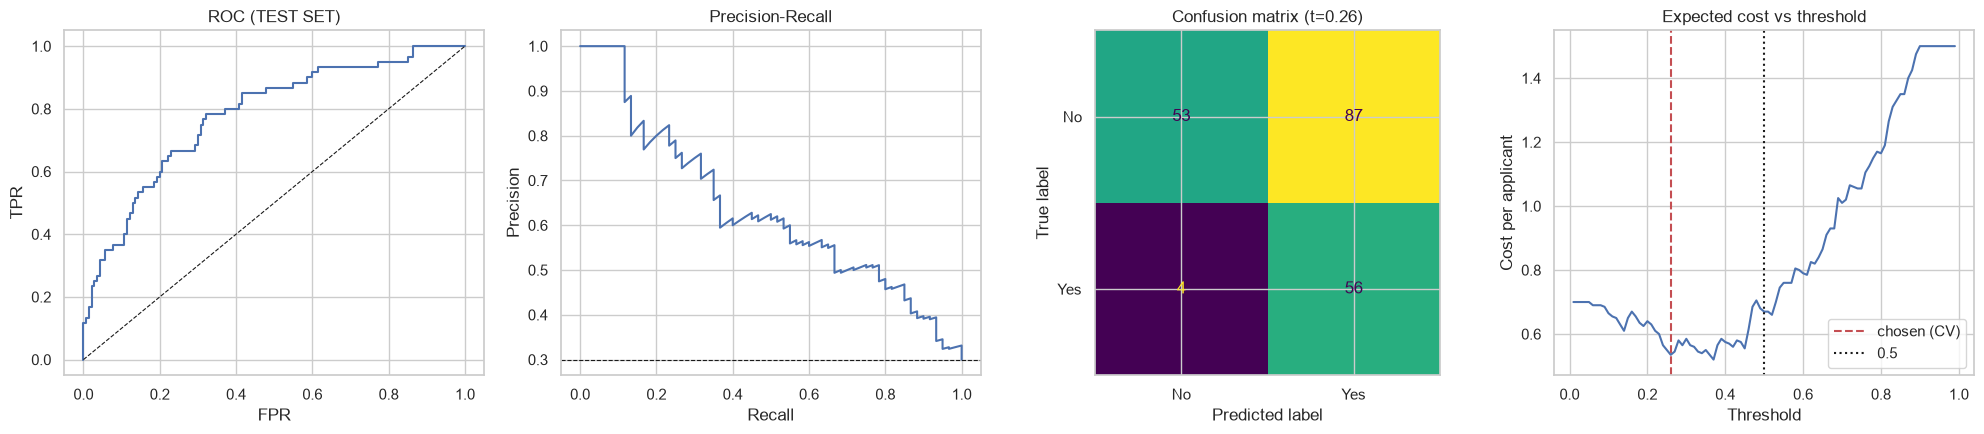

AdaBoost - TEST SET
Best params: {'clf__estimator__class_weight': None, 'clf__estimator__max_depth': 1, 'clf__learning_rate': 0.5, 'clf__n_estimators': 200}
CV AUC: 0.784 ± 0.041


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.773,0.625,0.591,0.433,0.50,0.22,0.94
t=0.39 (cost-opt),0.773,0.625,0.379,0.883,0.53,0.70,0.61


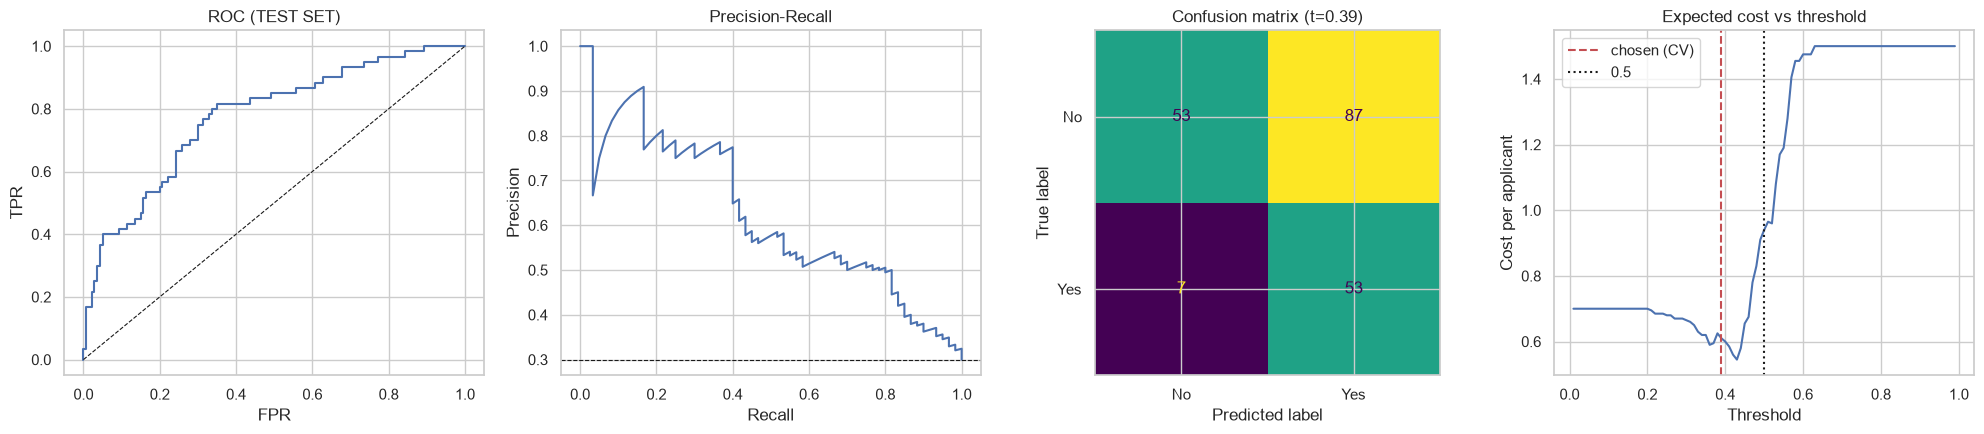

LightGBM - TEST SET
Best params: {'clf__colsample_bytree': 0.5, 'clf__learning_rate': 0.1, 'clf__min_child_samples': 20, 'clf__n_estimators': 100, 'clf__num_leaves': 15, 'clf__reg_lambda': 5.0}
CV AUC: 0.798 ± 0.036


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.751,0.633,0.558,0.483,0.518,0.260,0.890
t=0.10 (cost-opt),0.751,0.633,0.381,0.883,0.533,0.695,0.605


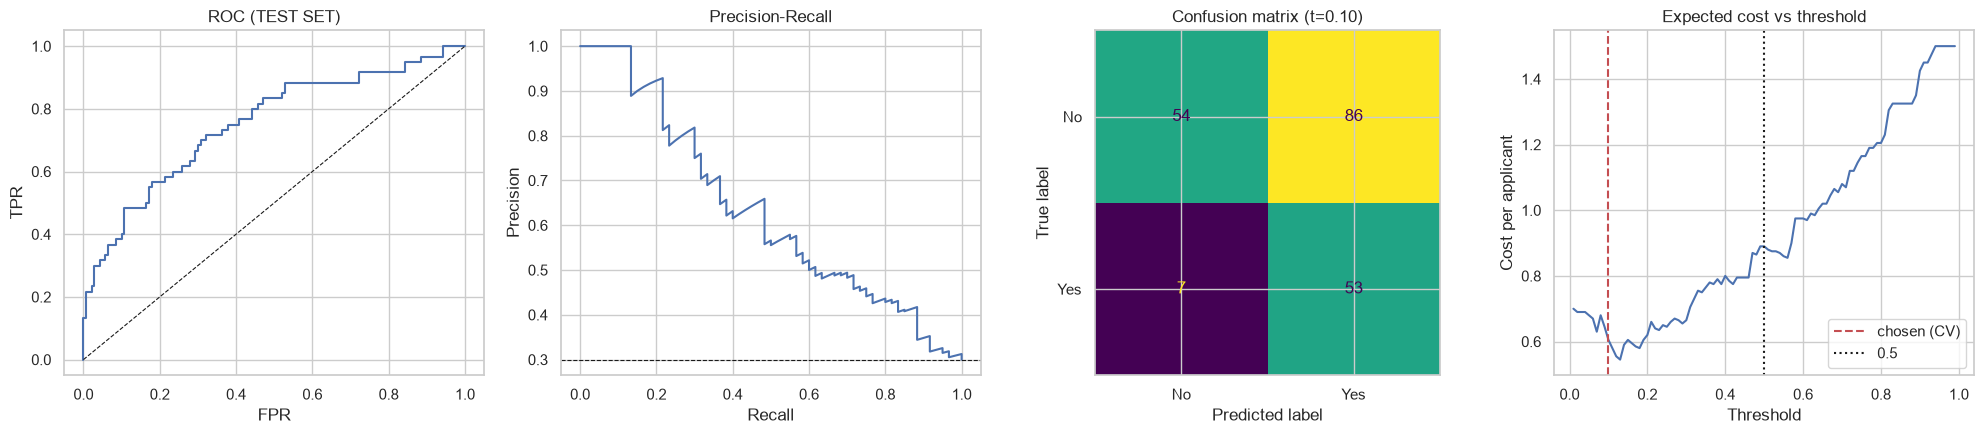

ANN - TEST SET
Best params: {'clf__dropout': 0.3, 'clf__hidden': (4,), 'clf__l2': 0.01}
CV AUC: 0.783 ± 0.053


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.782,0.618,0.611,0.367,0.458,0.18,1.02
t=0.16 (cost-opt),0.782,0.618,0.389,0.933,0.549,0.72,0.54


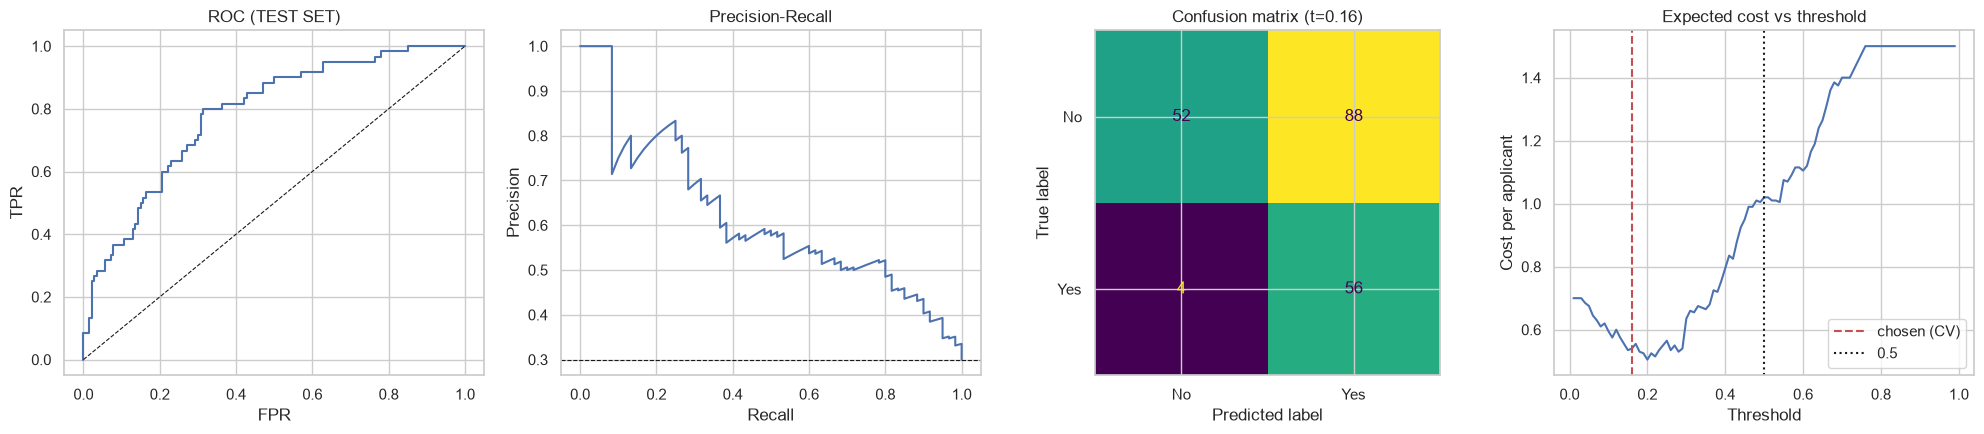

TEST SET


,cv_auc,cv_auc_std,threshold,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
Logistic Regression,0.777,0.053,0.17,0.770,0.604,0.376,0.883,0.527,0.705,0.615
Random Forest,0.792,0.047,0.37,0.792,0.640,0.398,0.850,0.543,0.640,0.610
XGBoost,0.803,0.039,0.26,0.779,0.636,0.392,0.933,0.552,0.715,0.535
AdaBoost,0.784,0.041,0.39,0.773,0.625,0.379,0.883,0.530,0.700,0.610
LightGBM,0.798,0.036,0.10,0.751,0.633,0.381,0.883,0.533,0.695,0.605
ANN,0.783,0.053,0.16,0.782,0.618,0.389,0.933,0.549,0.720,0.540
Approve all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,1.500
Reject all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.700


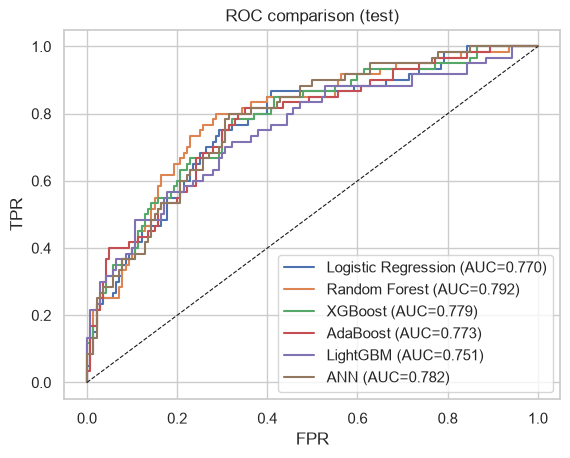

In [36]:
for res in results.values():
    common.evaluate(res, data)
    common.report(res, on="test")

common.compare(results.values(), on="test")

On the test set, `Random Forest` has the highest AUC (0.792, identical to its CV AUC of 0.792, so its ranking quality held up exactly), the highest average precision (0.640) and the highest precision at its threshold (0.398). Its cost per applicant at the CV-chosen threshold of 0.37 (0.610), however, is higher than `XGBoost` (0.535) and the `ANN` (0.540). At a threshold of 0.5 its test cost is 0.530, which suggests the CV-chosen threshold was slightly too conservative for this test sample. With only 200 test rows (60 defaulters) these differences are noisy, so the test results are read as confirmation that performance holds up rather than as a new ranking.

## Explainability (SHAP)

 99%|===================| 397/400 [00:25<00:00]        

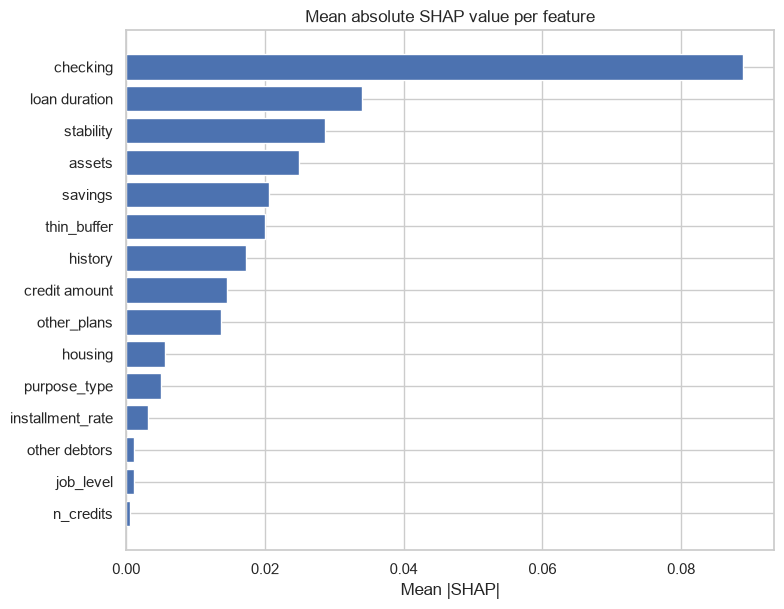

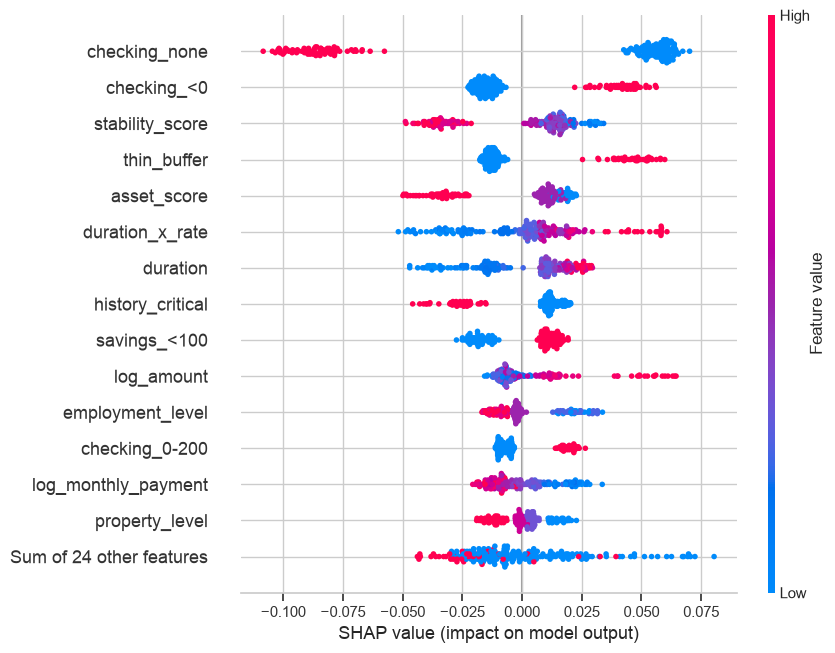

Highest risk: P(default) = 0.80


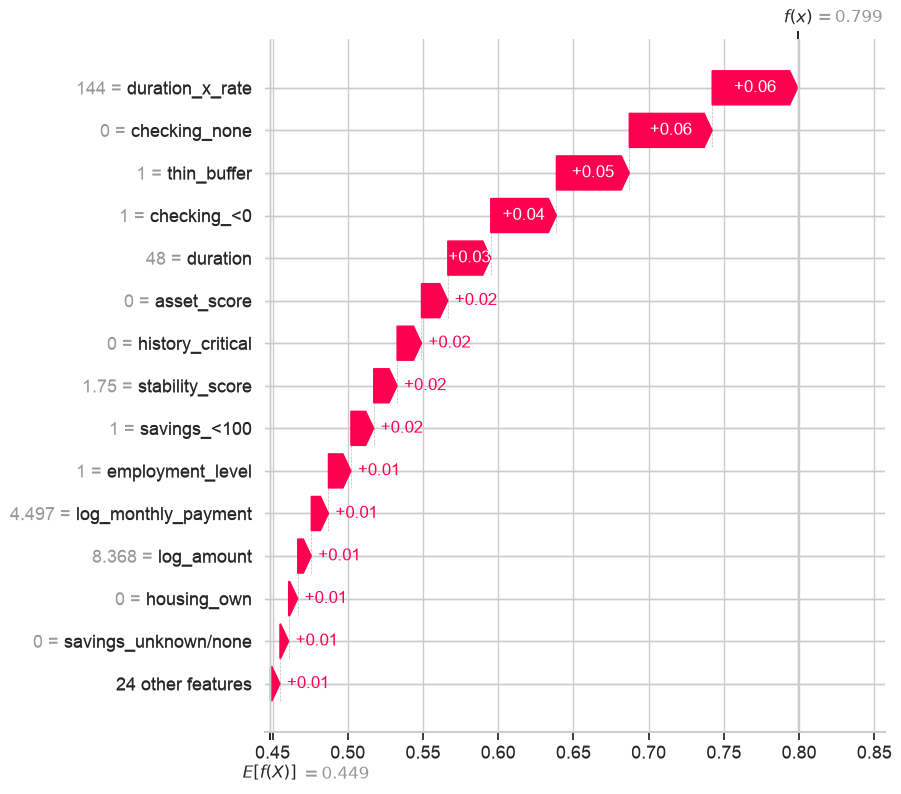

Closest to the decision threshold: P(default) = 0.37


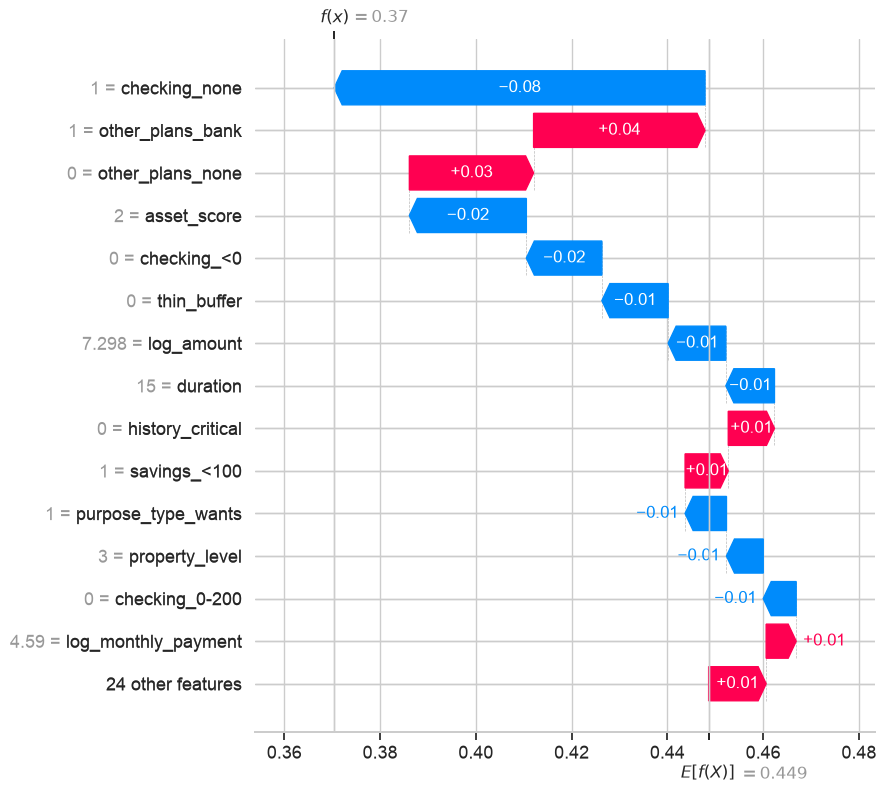

 99%|===================| 397/400 [00:26<00:00]        

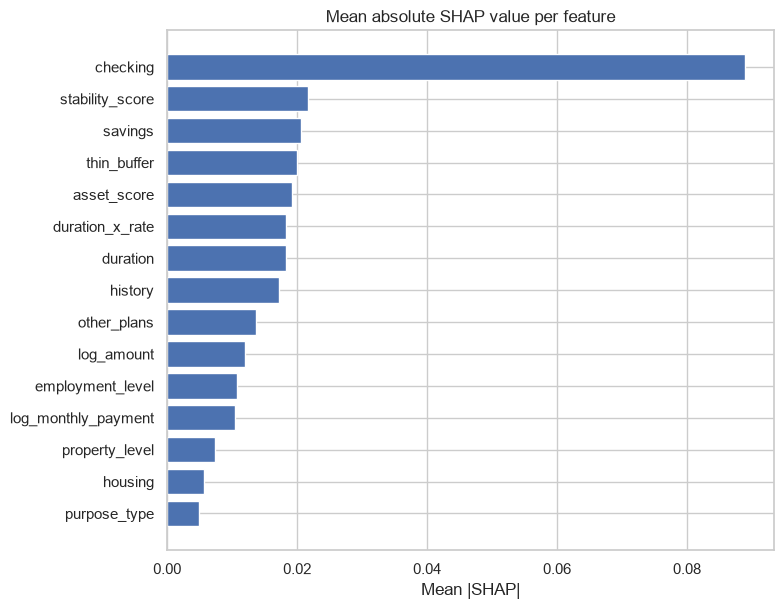

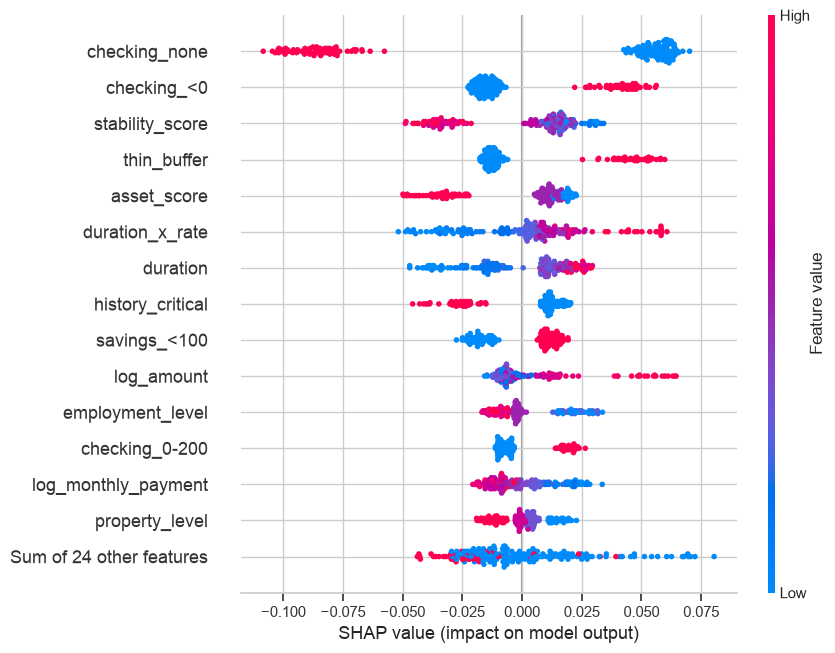

Highest risk: P(default) = 0.80


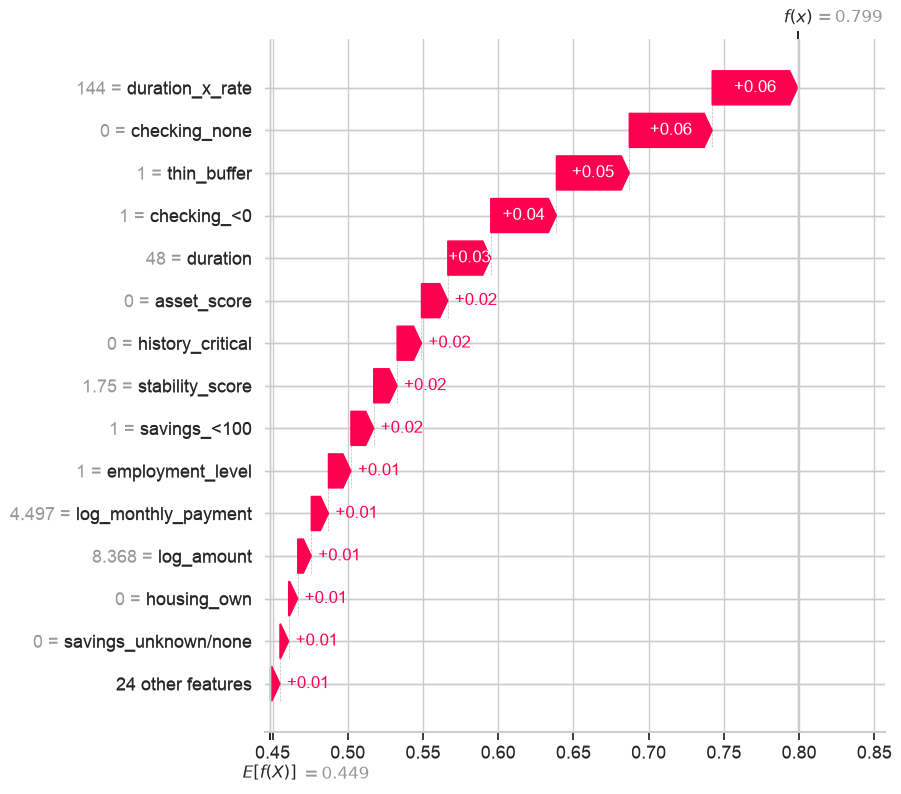

Closest to the decision threshold: P(default) = 0.37


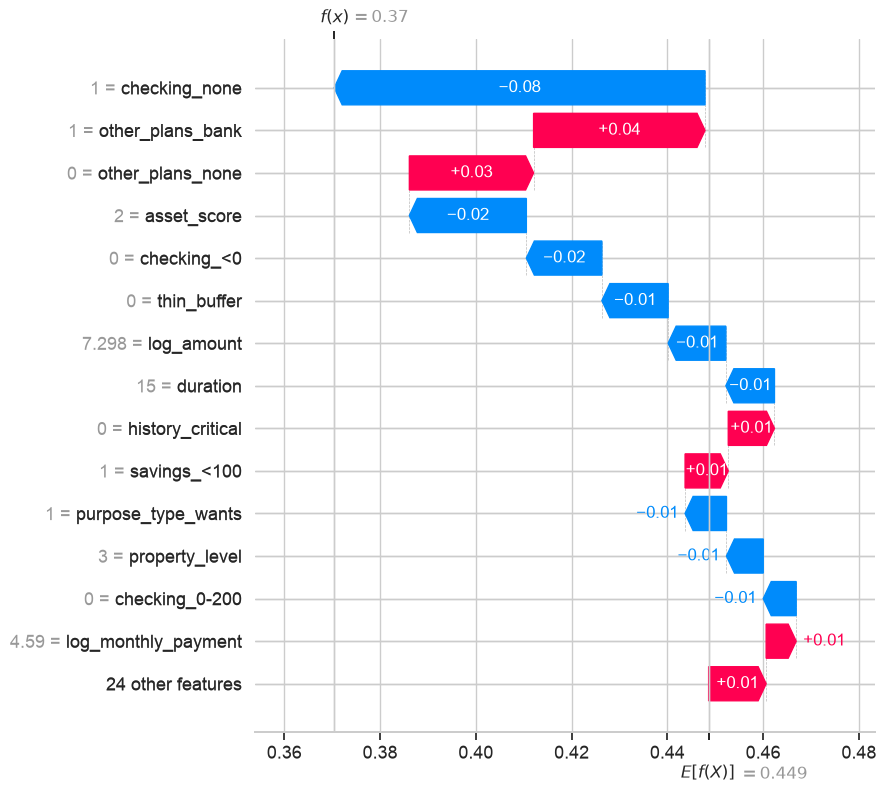

In [37]:
sv = common.explain(results["rf"], data)
sv2 = common.explain(results["rf"], data, merge = None)

Notes:
1. The first bar graph groups features to address the multicollinearity found in the EDA (credit amount = `log_amount` + `log_monthly_payment`; loan duration = `duration` + `duration_x_rate`; stability = `stability_score` + `employment_level`; assets = `asset_score` + `property_level`; other debtors = the guarantor and co-applicant flags). The one-hot dummy variables are also summed back into their original variable. Neither step is ideal, but both give a more reliable ranking than ignoring the problem. The report also mentions literature that argues in favour of grouping one-hot encoded categories. For `Random Forest`, SHAP values are in **probability units**: a value of 0.05 moves that applicant's predicted default probability by 5 percentage points.
2. `checking` dominates (mean |SHAP| ≈ 0.09, more than twice any other group), followed by loan duration (≈ 0.034), stability (≈ 0.029) and assets (≈ 0.025), then savings, `thin_buffer` and credit history (≈ 0.02 each). Credit amount ranks only eighth (≈ 0.015). The grouped values of multicollinear groups are likely slightly inflated, since their features are not perfectly correlated.
3. The ungrouped plots (beeswarm, and the second bar chart with `merge=None`) show the same picture: `checking`, `stability_score`, `savings`, `thin_buffer`, `asset_score` and the two duration features lead, and `log_amount` and `log_monthly_payment` sit lower. The beeswarm also shows the direction of each effect:
   - having **no checking account** lowers predicted risk sharply (about −8 points), while an **overdrawn account** (`checking_<0`) raises it (about +4 points);
   - **`thin_buffer`** (overdrawn and savings below 100 DM) raises risk by about 4–6 points, and savings below 100 DM on their own raise it by about 1–2 points;
   - **higher stability, assets, employment and property** scores lower risk;
   - **longer loans** (`duration`, `duration_x_rate`) and **larger amounts** raise risk;
   - a **"critical" credit history lowers predicted risk**. This mirrors the counter-intuitive pattern in the raw data and should be treated with caution (likely selection bias or a coding error in the dataset), not as a recommendation to favour such applicants.
   These directions are the basis for the business recommendations that follow.

## Fairness analysis

In [38]:
fair = common.fairness(results["rf"], data)

n  default_rate  approval_rate  \
attribute      group                                           
sex            female        61         0.328          0.377   
               male         139         0.288          0.353   
foreign_worker no             6         0.167          0.500   
               yes          194         0.304          0.356   
age_less_30    30 or under   83         0.422          0.265   
               over 30      117         0.214          0.427   

                            tpr (bad caught)  fpr (good rejected)    auc  \
attribute      group                                                       
sex            female                  0.800                0.537  0.778   
               male                    0.875                0.556  0.797   
foreign_worker no                      1.000                0.400  1.000   
               yes                     0.847                0.556  0.785   
age_less_30    30 or under             0.829                0.667  0.734   
               over 30                 0.880                0.489  0.835   

                            approval_ratio  
attribute      group                        
sex            female                1.000  
               male                  0.935  
foreign_worker no                    1.000  
               yes                   0.711  
age_less_30    30 or under           0.620  
               over 30               1.000

Notes:
1. As mentioned in the report, erroneous coding in the dataset leads to unreliable `sex` and `foreign_worker` labels which make a valid fairness analysis much harder to create. According to the corrected documentation, male singles and female non-singles share the same code, so `sex` cannot be fully recovered from `personal_status`. The coding check in the initial EDA also suggests the documented male labels are mislabelled, and no single female applicants exist (see Initial EDA, section 5). Similarly, `foreign_worker` categories appear to be flipped.
2. For `sex` the approval_ratio is well above the accepted bound of 0.8 (0.935 for the "male" group, which is approved slightly less often than the "female" group), providing support to the idea that there is no bias, but this could also be simply because of the errors in the data.
3. `foreign_worker` cannot be interpreted. The "yes" group has an approval ratio of 0.711, but it is compared against a "no" group of only 6 applicants, and the coding of this variable appears to be reversed.
4. For `age`, there is a clear difference between young people (30 or under) and older ones with the approval_ratio for the younger category being 0.620. This is clear evidence of disparate impact, per the 0.8 threshold, even though age is not a model input: the model reaches age indirectly through correlated features. Creditworthy young applicants are also rejected more often (false positive rate 0.667 vs 0.489 for those over 30). However, arguments can be made whether `age` should be a bias variable or not, since `age` is often correlated with financial health and savings making any bias a reflection of other variables.